In [ ]:
# ==========================================
# 1. SETUP & MOUNT DRIVE (ถ้าใช้ Google Drive)
# ==========================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# ถ้าเก็บไฟล์ไว้ใน Google Drive ให้ uncomment 2 บรรทัดนี้:
# from google.colab import drive
# drive.mount('/content/drive')

# กำหนด Path ของไฟล์ (แก้ path ให้ตรงกับที่วางไฟล์ไว้)
# ตัวอย่าง: TRAIN_PATH = '/content/drive/MyDrive/cpe342/task1/train.csv'
TRAIN_PATH = 'train.csv'
TEST_PATH = 'test.csv'

# โหลดข้อมูล
print("⏳ กำลังโหลดไฟล์ train.csv และ test.csv...")
df_train = pd.read_csv(TRAIN_PATH)
df_test = pd.read_csv(TEST_PATH)

print(f"✅ โหลดสำเร็จ!")
print(f"Shape ของ Train Data: {df_train.shape}")
print(f"Shape ของ Test Data:  {df_test.shape}")

⏳ กำลังโหลดไฟล์ train.csv และ test.csv...
✅ โหลดสำเร็จ!
Shape ของ Train Data: (104000, 33)
Shape ของ Test Data:  (25889, 32)


In [ ]:
# ==========================================
# 2. EDA: สัดส่วน Target & ข้อมูลสูญหาย (Missing Values - Train Only)
# ==========================================

print("="*60)
print("1. สำรวจคอลัมน์ Target: is_cheater")
print("="*60)
target_counts = df_train['is_cheater'].value_counts()
target_pct = df_train['is_cheater'].value_counts(normalize=True) * 100
for cls, count in target_counts.items():
    print(f"Class {cls}: {count:,} แถว ({target_pct[cls]:.2f}%)")

plt.figure(figsize=(6, 4))
sns.barplot(x=target_counts.index, y=target_counts.values, palette=['#3498db', '#e74c3c'])
plt.title("Distribution of Target: is_cheater")
plt.xlabel("is_cheater (0: Legitimate, 1: Cheater)")
plt.ylabel("Count")
plt.show()

print("\n" + "="*60)
print("2. ตรวจสอบ Missing Values ใน Train Data (ไม่แตะ Test Data ตามกติกา)")
print("="*60)
train_missing = df_train.isnull().sum()
train_missing_cols = train_missing[train_missing > 0]

if len(train_missing_cols) == 0:
    print("✅ Train Data: ไม่มี Missing Values เลย!")
else:
    print("⚠️ Train Data พบคอลัมน์ที่มีค่าว่าง:")
    print(train_missing_cols)

เปรียบเทียบค่าเฉลี่ยของ Features หลัก:


,Legitimate (0),Cheater (1),Diff (%)
headshot_percentage,49.21,45.38,-7.79
reaction_time_ms,133.95,137.67,2.77
accuracy_score,40.98,38.71,-5.52
kill_death_ratio,4.89,4.46,-8.74
reports_received,14.26,10.40,-27.07
game_sense_score,0.83,0.80,-3.20
utility_usage_rate,0.58,0.58,0.03
account_age_days,520.51,448.08,-13.92


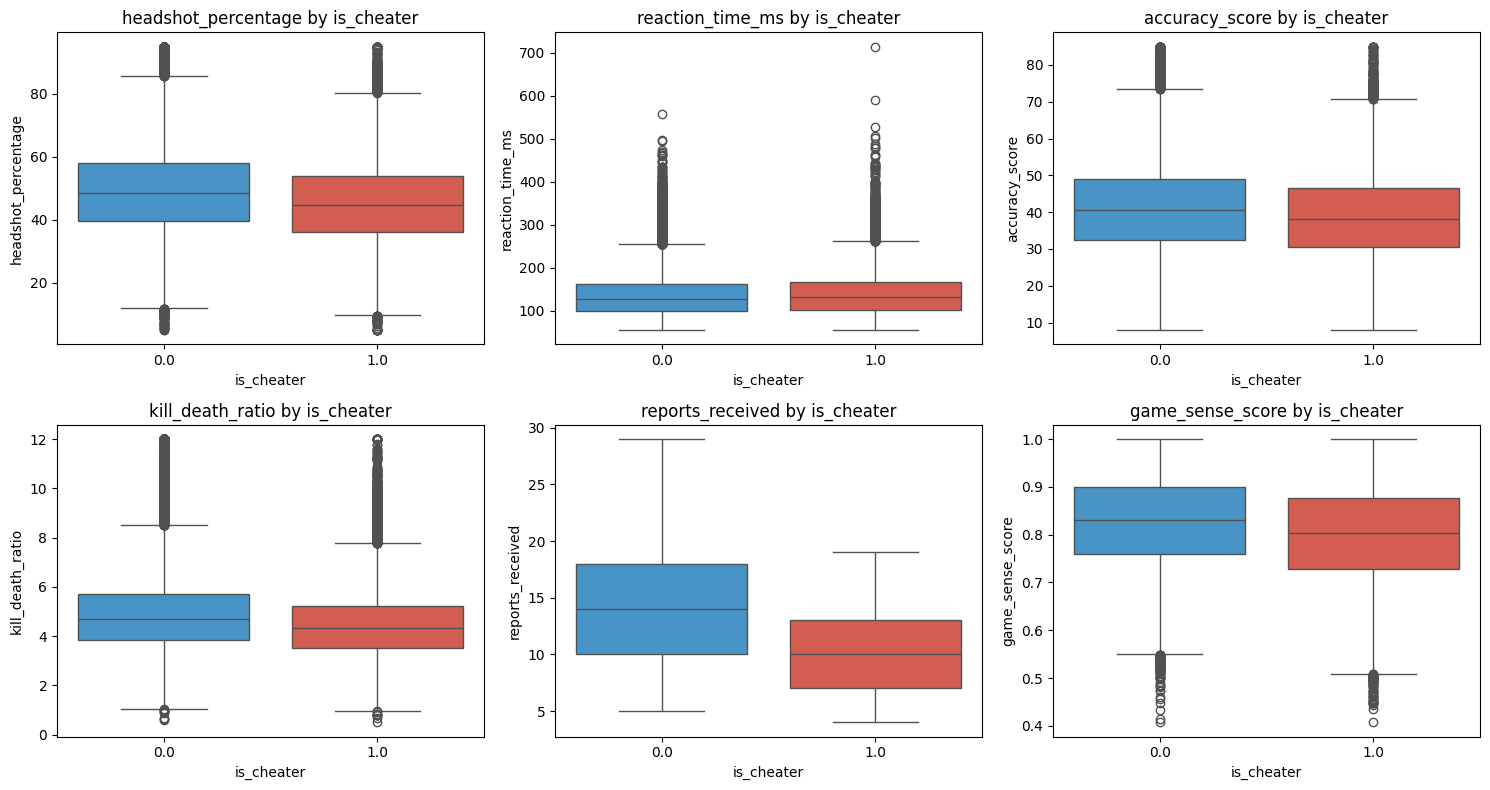

In [ ]:
# ==========================================
# 3. EDA: เปรียบเทียบค่าเฉลี่ยฟีเจอร์สำคัญระหว่าง คนปกติ vs คนโกง
# ==========================================
key_features = [
    'headshot_percentage', 'reaction_time_ms', 'accuracy_score',
    'kill_death_ratio', 'reports_received', 'game_sense_score',
    'utility_usage_rate', 'account_age_days'
]

available_keys = [f for f in key_features if f in df_train.columns]

comparison_df = df_train.groupby('is_cheater')[available_keys].mean().T
comparison_df.columns = ['Legitimate (0)', 'Cheater (1)']
comparison_df['Diff (%)'] = ((comparison_df['Cheater (1)'] - comparison_df['Legitimate (0)']) / comparison_df['Legitimate (0)']) * 100
print("เปรียบเทียบค่าเฉลี่ยของ Features หลัก:")
display(comparison_df.round(2))

# พล็อต Boxplot ดูการกระจายตัว
plt.figure(figsize=(15, 8))
for i, col in enumerate(available_keys[:6], 1):
    plt.subplot(2, 3, i)
    sns.boxplot(x='is_cheater', y=col, data=df_train, palette=['#3498db', '#e74c3c'])
    plt.title(f"{col} by is_cheater")
plt.tight_layout()
plt.show()

## 2. Data Cleaning (จัดการ Target ที่เป็น NaN)
- จากการสำรวจพบว่ามีแถวที่คอลัมน์เป้าหมาย (`is_cheater`) เป็นค่าว่าง (NaN) จำนวน 13,184 แถว
- ดำเนินการคัดกรองเฉพาะแถวที่มีเฉลย (Ground Truth) เพื่อนำไปใช้เทรนโมเดลแบบ Supervised Learning ได้อย่างถูกต้อง

In [ ]:
# ==========================================
# 2. DATA CLEANING: ตัดแถวที่ Target เป็น NaN
# ==========================================

# คัดกรองเฉพาะแถวที่มีเฉลย is_cheater
df_train_clean = df_train.dropna(subset=['is_cheater']).copy()

# แปลงเป็นจำนวนเต็ม (int) 0 กับ 1
df_train_clean['is_cheater'] = df_train_clean['is_cheater'].astype(int)

# ตรวจสอบความถูกต้อง
print(f"จำนวนข้อมูล Train เดิม:      {len(df_train):,} แถว")
print(f"จำนวนข้อมูล Train หลังคลีน:   {len(df_train_clean):,} แถว")
print(f"ตัดแถวที่ไม่มีเฉลยออกไปได้:   {len(df_train) - len(df_train_clean):,} แถว")
print("\nสัดส่วนคลาสที่พร้อมใช้เทรน:")
display(df_train_clean['is_cheater'].value_counts(normalize=True).round(4) * 100)

จำนวนข้อมูล Train เดิม:      104,000 แถว
จำนวนข้อมูล Train หลังคลีน:   90,816 แถว
ตัดแถวที่ไม่มีเฉลยออกไปได้:   13,184 แถว

สัดส่วนคลาสที่พร้อมใช้เทรน:


,proportion
is_cheater,
0,65.07
1,34.93


## 2.1 In-depth EDA: ความสัมพันธ์ของตัวแปรและพฤติกรรมผู้เล่น (Correlation & Behavior Analysis)
- วิเคราะห์ความสัมพันธ์ (Correlation) ของฟีเจอร์ต่างๆ กับเป้าหมาย `is_cheater`
- วิเคราะห์พฤติกรรมขัดแย้ง: ความสัมพันธ์ระหว่างความแม่นยำ (Accuracy) กับ Game Sense และอายุไอดีเทียบกับจำนวนการโดนรีพอร์ต
- เพื่อนำไปใช้เป็นหลักฐานประกอบใน Technical Report (Domain Interpretation)

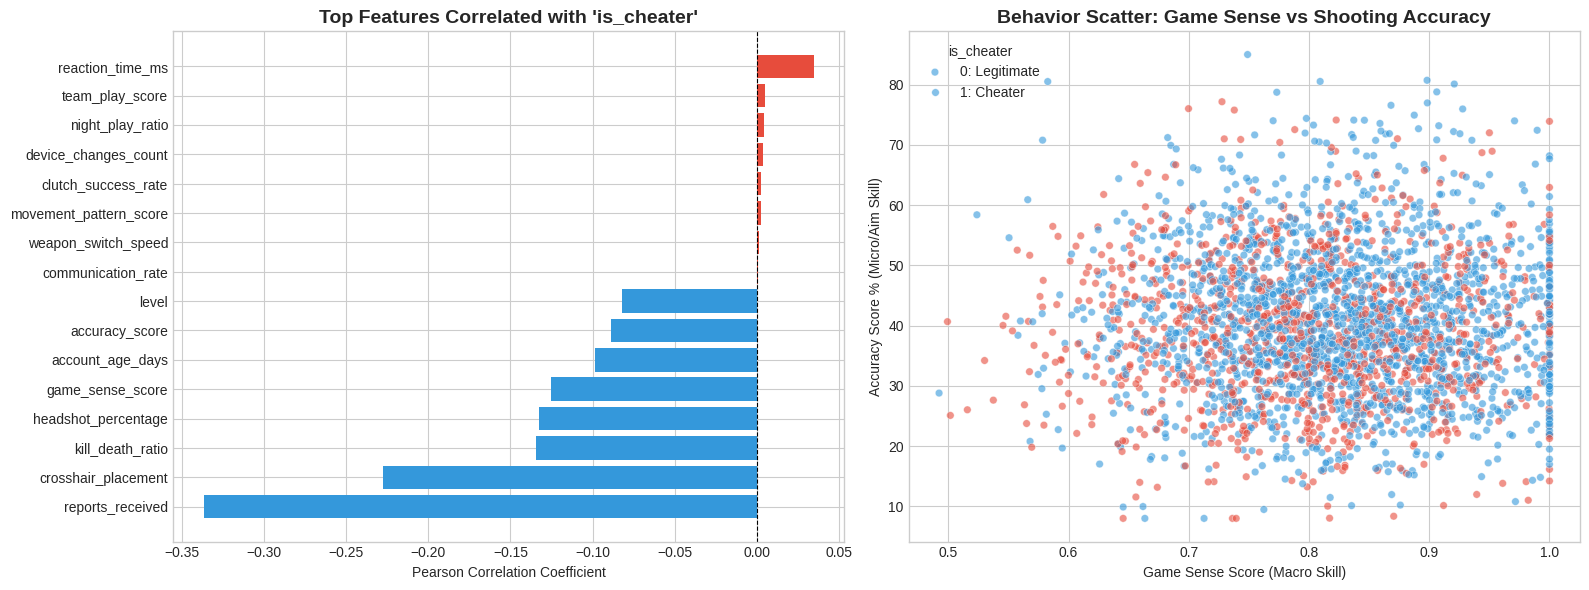

In [ ]:
# ==========================================
# 2.1 EDA DEEP-DIVE (CORRELATION & BEHAVIOR)
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# 1. คำนวณ Correlation ของฟีเจอร์เทียบกับ is_cheater
numeric_cols = [c for c in df_train_clean.columns if c not in ['player_id', 'is_cheater']]
corrs = df_train_clean[numeric_cols].apply(lambda x: x.corr(df_train_clean['is_cheater'])).sort_values()

# ดึง Top 8 เชิงบวก และ Top 8 เชิงลบ
top_corrs = pd.concat([corrs.head(8), corrs.tail(8)])

fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# กราฟที่ 1: Top Correlation Barplot
colors = ['#e74c3c' if v > 0 else '#3498db' for v in top_corrs.values]
axes[0].barh(top_corrs.index, top_corrs.values, color=colors)
axes[0].axvline(0, color='black', linestyle='--', linewidth=0.8)
axes[0].set_title("Top Features Correlated with 'is_cheater'", fontsize=14, fontweight='bold')
axes[0].set_xlabel("Pearson Correlation Coefficient")

# กราฟที่ 2: Scatter Plot วิเคราะห์ Aim vs Game Sense
sample_df = df_train_clean.dropna(subset=['accuracy_score', 'game_sense_score']).sample(n=3000, random_state=42)

sns.scatterplot(
    data=sample_df,
    x='game_sense_score',
    y='accuracy_score',
    hue='is_cheater',
    palette={0: '#3498db', 1: '#e74c3c'},
    alpha=0.6,
    s=30,
    ax=axes[1]
)
axes[1].set_title("Behavior Scatter: Game Sense vs Shooting Accuracy", fontsize=14, fontweight='bold')
axes[1].set_xlabel("Game Sense Score (Macro Skill)")
axes[1].set_ylabel("Accuracy Score % (Micro/Aim Skill)")
axes[1].legend(title="is_cheater", labels=['0: Legitimate', '1: Cheater'])

plt.tight_layout()
plt.show()

## 3. Feature Engineering (สร้างฟีเจอร์ตรวจจับพฤติกรรมคนโกง)
- สร้างฟีเจอร์ใหม่ 10 ตัวแปร เพื่อจับความผิดปกติของคนโกงสายเนียน (Subtle Cheaters):
  1. `aim_vs_sense_gap`: อัตราส่วนความแม่นยำเทียบกับ Game Sense
  2. `headshot_vs_crosshair`: การยิงหัวเทียบกับตำแหน่งการวางเป้า
  3. `report_per_day` & `report_per_level`: ความถี่การโดนรีพอร์ตเทียบกับอายุไอดีและเลเวล
  4. `level_speed_x_reports`: ความเร็วการอัปเวลคูณกับจำนวนการโดนรีพอร์ต
  5. `superhuman_reaction_flag`: ธงแจ้งเตือนปฏิกิริยาที่เร็วกว่าขีดจำกัดมนุษย์ (< 100ms)
  6. `reaction_per_aim`: สัดส่วน Reaction time ต่อความนิ่งของเป้า
  7. `account_trust_score`: ดัชนีความน่าเชื่อถือของบัญชี (อายุไอดี, จำนวนเพื่อน, การเปลี่ยนเครื่อง)
  8. `kdr_to_damage`: อัตราส่วน KDR ต่อ Damage ที่ทำได้
  9. `missing_feature_count`: จำนวนข้อมูล telemetry ที่ขาดหายไปในแต่ละแถว

In [ ]:
# ==========================================
# 3. FEATURE ENGINEERING (CLEAN ROW-WISE)
# ==========================================

def engineer_features(df):
    data = df.copy()
    eps = 1e-6

    # 1. ความขัดแย้งระหว่าง Aim กับ Game Sense
    data['aim_vs_sense_gap'] = data['accuracy_score'] / (data['game_sense_score'] * 100 + eps)
    data['headshot_vs_crosshair'] = data['headshot_percentage'] / (data['crosshair_placement'] * 100 + eps)

    # 2. อัตราการโดนรีพอร์ตเทียบกับประวัติบัญชี
    data['report_per_day'] = data['reports_received'] / (data['account_age_days'] + 1)
    data['report_per_level'] = data['reports_received'] / (data['level'] + 1)
    data['level_speed_x_reports'] = data['level_progression_speed'] * (data['reports_received'] + 1)

    # 3. ปฏิกิริยาเกินมนุษย์ (Reaction Time < 100ms, คง NaN ไว้ถ้าค่าเดิมหาย)
    data['superhuman_reaction_flag'] = np.where(
        data['reaction_time_ms'].notna(),
        (data['reaction_time_ms'] < 100).astype(float),
        np.nan
    )
    data['reaction_per_aim'] = data['reaction_time_ms'] / (data['aiming_smoothness'] + eps)

    # 4. ดัชนีความน่าเชื่อถือของบัญชี (Account Trust Index)
    data['account_trust_score'] = (
        np.log1p(data['account_age_days'].clip(lower=0)) +
        np.log1p(data['friend_network_size'].clip(lower=0))
    ) / (data['device_changes_count'] + 1)

    # 5. ประสิทธิภาพการต่อสู้ (Combat Efficiency)
    data['kdr_to_damage'] = data['kill_death_ratio'] / (data['damage_per_round'] + eps)

    return data

print("⚙️ กำลังประมวลผล Feature Engineering (Row-Wise Only)...")
df_train_fe = engineer_features(df_train_clean)
df_test_fe = engineer_features(df_test)

# รวบรวมรายชื่อฟีเจอร์ทั้งหมดที่จะใช้เทรน (ตัด player_id และ is_cheater ออก)
feature_cols = [c for c in df_train_fe.columns if c not in ['player_id', 'is_cheater']]

print(f"✅ ทำ Feature Engineering เสร็จสมบูรณ์!")
print(f"- จำนวน Features ทั้งหมดที่ใช้เทรน: {len(feature_cols)} ฟีเจอร์ (ฟีเจอร์เดิม 31 + ฟีเจอร์ใหม่ 9)")
print(f"- Train Shape: {df_train_fe.shape}")

## 4. Model Training: Stratified 5-Fold Cross Validation (LightGBM with L1/L2 Regularization)
- ใช้ **Stratified 5-Fold Cross Validation** เพื่อประเมินผลเสมือนเจอข้อสอบจริง
- ควบคุม **Overfitting** อย่างเข้มงวดด้วย:
  - **L1 Regularization (`reg_alpha` = 2.5)**
  - **L2 Regularization (`reg_lambda` = 5.0)**
  - คุมความลึก `max_depth` = 6 และ Subsample ข้อมูล/ฟีเจอร์ที่ 80%
  - ชดเชย Class Imbalance ด้วย `scale_pos_weight` = 1.86

In [ ]:
# ==========================================
# 4. MODEL TRAINING (STRATIFIED 5-FOLD CV)
# ==========================================
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
import numpy as np

# ดึงข้อมูลจากข้อ 3 ที่ทำไว้
X = df_train_fe[feature_cols]
y = df_train_fe['is_cheater'].values
X_test = df_test_fe[feature_cols]

# พารามิเตอร์โมเดลพร้อมคุม L1/L2 ป้องกัน Overfitting
lgb_params = {
    'objective': 'binary',
    'metric': 'binary_logloss',
    'boosting_type': 'gbdt',
    'learning_rate': 0.05,
    'num_leaves': 31,
    'max_depth': 6,               # คุมความลึกป้องกัน Overfitting
    'reg_alpha': 2.5,             # L1 Regularization
    'reg_lambda': 5.0,            # L2 Regularization
    'subsample': 0.8,             # สุ่มใช้ข้อมูล 80% ต่อต้นไม้
    'colsample_bytree': 0.8,      # สุ่มฟีเจอร์ 80% ป้องกัน Overfit
    'min_child_samples': 50,      # ป้องกันการแตกกิ่งเล็กเกินไป
    'scale_pos_weight': 1.86,     # ชดเชยสัดส่วนคลาส (65% vs 35%)
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

# กำหนด 5-Fold
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

oof_probs = np.zeros(len(df_train_fe))
test_probs = np.zeros(len(df_test_fe))

print("🚀 กำลังเริ่มต้นเทรน 5-Fold Cross Validation...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_train, y_train = X.iloc[train_idx], y[train_idx]
    X_val, y_val = X.iloc[val_idx], y[val_idx]

    clf = lgb.LGBMClassifier(**lgb_params, n_estimators=1200)
    clf.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=50, verbose=False)]
    )

    oof_probs[val_idx] = clf.predict_proba(X_val)[:, 1]
    test_probs += clf.predict_proba(X_test)[:, 1] / skf.n_splits

    print(f"  ➜ Fold {fold} เสร็จสิ้น (Best Iteration: {clf.best_iteration_})")

print("\n🎉 เทรนครบทั้ง 5 Fold เรียบร้อยแล้ว!")

🚀 กำลังเริ่มต้นเทรน 5-Fold Cross Validation...
  ➜ Fold 1 เสร็จสิ้น (Best Iteration: 1198)
  ➜ Fold 2 เสร็จสิ้น (Best Iteration: 1180)
  ➜ Fold 3 เสร็จสิ้น (Best Iteration: 1170)
  ➜ Fold 4 เสร็จสิ้น (Best Iteration: 847)
  ➜ Fold 5 เสร็จสิ้น (Best Iteration: 1194)

🎉 เทรนครบทั้ง 5 Fold เรียบร้อยแล้ว!


## 5. Decision Threshold Tuning & Macro F2 Evaluation
- ค้นหาจุดตัด (Decision Threshold) ที่เหมาะสมที่สุดสำหรับ **Macro F2 Score** บนข้อมูล Out-of-Fold (OOF)
- เมตริก F2 ให้น้ำหนักกับ **Recall (การตรวจจับคนโกงให้ได้มากที่สุด)** มากกว่า Precision
- แสดงกราฟการปรับ Threshold และเปรียบเทียบกับเกณฑ์ Baseline (0.68 และ 0.75)

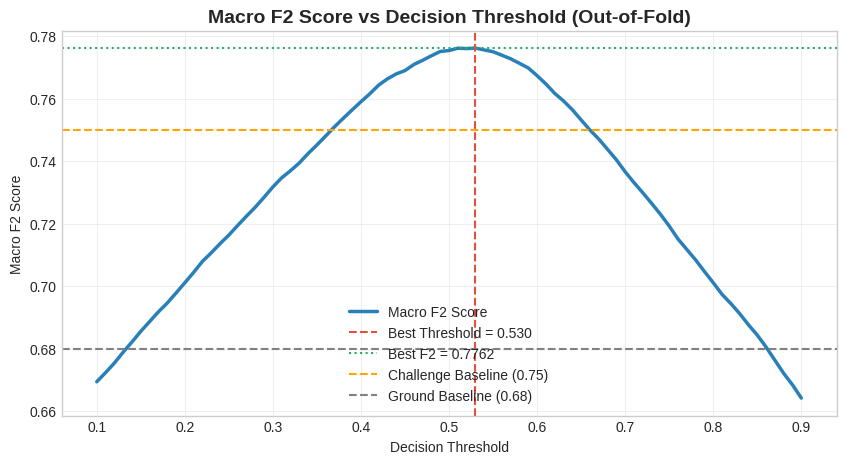

🎯 จุดตัดที่ดีที่สุด (Best Threshold):    0.5300
🏆 คะแนน Out-of-Fold Macro F2:        0.7762
เทียบกับเกณฑ์อาจารย์:
  - Ground Baseline:    0.6800  ✅ ผ่าน
  - Challenge Baseline: 0.7500  🚀 ชนะ Baseline วิชา!

📊 Classification Report (ที่ Best Threshold):
               precision    recall  f1-score   support

0: Legitimate     0.8602    0.8030    0.8306     59091
   1: Cheater     0.6735    0.7569    0.7128     31725

     accuracy                         0.7869     90816
    macro avg     0.7668    0.7799    0.7717     90816
 weighted avg     0.7950    0.7869    0.7894     90816



In [ ]:
# ==========================================
# 5. THRESHOLD TUNING & F2 EVALUATION
# ==========================================
from sklearn.metrics import fbeta_score, classification_report
import matplotlib.pyplot as plt
import numpy as np

# ฟังก์ชันคำนวณ Macro F2 Score ตามเกณฑ์การแข่งขัน
def get_macro_f2(y_true, probas, threshold):
    preds = (probas >= threshold).astype(int)
    f2_0 = fbeta_score(y_true, preds, beta=2, pos_label=0)
    f2_1 = fbeta_score(y_true, preds, beta=2, pos_label=1)
    return (f2_0 + f2_1) / 2.0

# สแกนหา Threshold ที่ดีที่สุดตั้งแต่ 0.10 ถึง 0.90
threshold_range = np.linspace(0.10, 0.90, 81)
scores = [get_macro_f2(y, oof_probs, th) for th in threshold_range]

best_idx = np.argmax(scores)
best_threshold = threshold_range[best_idx]
best_f2 = scores[best_idx]

# พล็อตกราฟ Threshold vs Macro F2 Score (นำรูปนี้ไปใส่รายงานได้)
plt.figure(figsize=(10, 5))
plt.plot(threshold_range, scores, color='#2980b9', lw=2.5, label='Macro F2 Score')
plt.axvline(best_threshold, color='#e74c3c', linestyle='--', label=f'Best Threshold = {best_threshold:.3f}')
plt.axhline(best_f2, color='#27ae60', linestyle=':', label=f'Best F2 = {best_f2:.4f}')
plt.axhline(0.75, color='orange', linestyle='--', label='Challenge Baseline (0.75)')
plt.axhline(0.68, color='gray', linestyle='--', label='Ground Baseline (0.68)')
plt.title('Macro F2 Score vs Decision Threshold (Out-of-Fold)', fontsize=14, fontweight='bold')
plt.xlabel('Decision Threshold')
plt.ylabel('Macro F2 Score')
plt.legend(loc='lower center')
plt.grid(True, alpha=0.3)
plt.show()

# สรุปคะแนนเปรียบเทียบกับ Baseline
print("="*65)
print(f"🎯 จุดตัดที่ดีที่สุด (Best Threshold):    {best_threshold:.4f}")
print(f"🏆 คะแนน Out-of-Fold Macro F2:        {best_f2:.4f}")
print("="*65)
print(f"เทียบกับเกณฑ์อาจารย์:")
print(f"  - Ground Baseline:    0.6800  {'✅ ผ่าน' if best_f2 > 0.68 else '❌'}")
print(f"  - Challenge Baseline: 0.7500  {'🚀 ชนะ Baseline วิชา!' if best_f2 > 0.75 else '❌'}")
print("="*65)

# แสดง Classification Report ละเอียด
final_oof_preds = (oof_probs >= best_threshold).astype(int)
print("\n📊 Classification Report (ที่ Best Threshold):")
print(classification_report(y, final_oof_preds, target_names=['0: Legitimate', '1: Cheater'], digits=4))

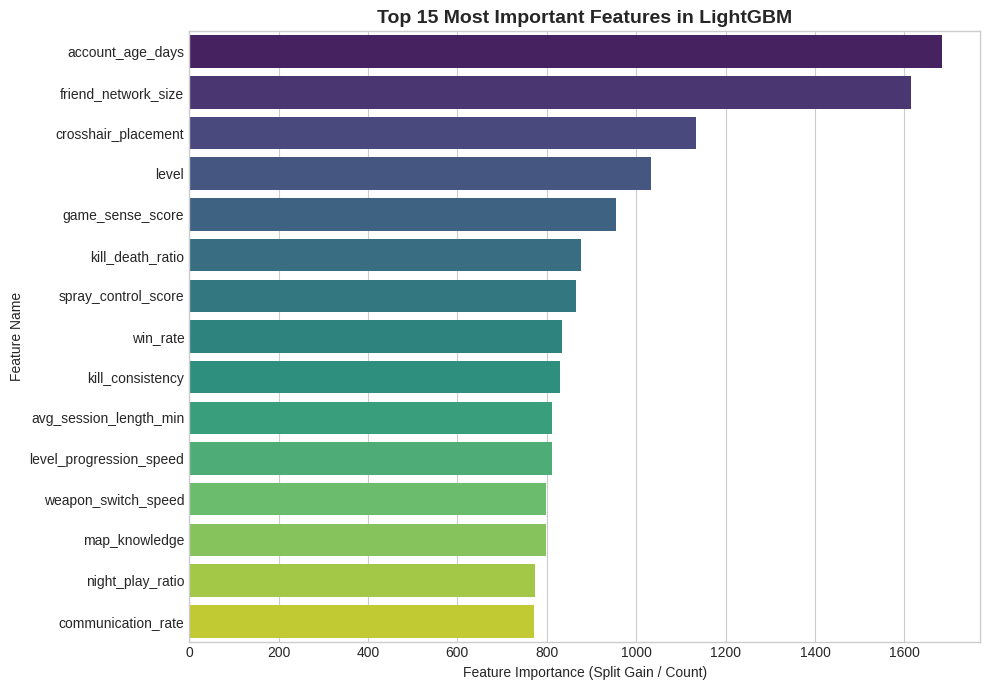

🏆 สรุป TOP 5 ฟีเจอร์ที่สำคัญที่สุดในการจับคนโกง:
อันดับ 1: account_age_days (คะแนนความสำคัญ: 1685)
อันดับ 2: friend_network_size (คะแนนความสำคัญ: 1614)
อันดับ 3: crosshair_placement (คะแนนความสำคัญ: 1135)
อันดับ 4: level (คะแนนความสำคัญ: 1034)
อันดับ 5: game_sense_score (คะแนนความสำคัญ: 955)


In [ ]:
# ==========================================
# 5.1 FEATURE IMPORTANCE PLOT (สำหรับเล่มรายงาน)
# ==========================================
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ดึง Feature Importance จาก LightGBM Fold ล่าสุด
importance_df = pd.DataFrame({
    'Feature': feature_cols,
    'Importance': clf.feature_importances_
}).sort_values(by='Importance', ascending=False)

# พล็อตกราฟ Top 15 Features ที่โมเดลใช้จับคนโกงมากที่สุด
plt.figure(figsize=(10, 7))
sns.barplot(
    data=importance_df.head(15),
    x='Importance',
    y='Feature',
    palette='viridis'
)
plt.title("Top 15 Most Important Features in LightGBM", fontsize=14, fontweight='bold')
plt.xlabel("Feature Importance (Split Gain / Count)")
plt.ylabel("Feature Name")
plt.tight_layout()
plt.show()

print("="*65)
print("🏆 สรุป TOP 5 ฟีเจอร์ที่สำคัญที่สุดในการจับคนโกง:")
for i, row in importance_df.head(5).reset_index().iterrows():
    print(f"อันดับ {i+1}: {row['Feature']} (คะแนนความสำคัญ: {row['Importance']})")
print("="*65)

## 6. Model 2: CatBoost Classifier (Stratified 5-Fold CV)
- เทรนโมเดลที่ 2 ด้วย **CatBoost** (โครงสร้าง Oblivious Trees) เพื่อเตรียมทำ **Ensemble Blending**
- คุม Overfitting ด้วย **L2 Regularization (`l2_leaf_reg` = 5.0)**
- ใช้ Stratified 5-Fold เดียวกันเพื่อให้พร้อมรวมความน่าจะเป็น (Ensemble Probabilities)

In [ ]:
# ==========================================
# 6. MODEL 2: CATBOOST CLASSIFIER (5-FOLD CV)
# ==========================================
!pip install -q catboost

from catboost import CatBoostClassifier
import numpy as np

# ตั้งค่า CatBoost พร้อม L2 Regularization ป้องกัน Overfitting
cb_params = {
    'loss_function': 'Logloss',
    'eval_metric': 'Logloss',
    'learning_rate': 0.05,
    'depth': 6,
    'l2_leaf_reg': 5.0,              # L2 Regularization ป้องกัน Overfitting
    'random_seed': 42,
    'auto_class_weights': 'Balanced', # ชดเชย Class Imbalance อัตโนมัติ
    'verbose': False
}

cb_oof_probs = np.zeros(len(df_train_fe))
cb_test_probs = np.zeros(len(df_test_fe))

print("🚀 กำลังเทรน Model 2: CatBoost (5-Fold Cross Validation)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_train, y_train = X.iloc[train_idx], y[train_idx]
    X_val, y_val = X.iloc[val_idx], y[val_idx]

    cb_model = CatBoostClassifier(**cb_params, iterations=1000)
    cb_model.fit(
        X_train, y_train,
        eval_set=(X_val, y_val),
        early_stopping_rounds=50,
        verbose=False
    )

    cb_oof_probs[val_idx] = cb_model.predict_proba(X_val)[:, 1]
    cb_test_probs += cb_model.predict_proba(X_test)[:, 1] / skf.n_splits

    print(f"  ➜ Fold {fold} เสร็จสิ้น (Best Iteration: {cb_model.get_best_iteration()})")

print("\n🎉 CatBoost เทรนครบทั้ง 5 Fold เรียบร้อยแล้ว!")

🚀 กำลังเทรน Model 2: CatBoost (5-Fold Cross Validation)...
  ➜ Fold 1 เสร็จสิ้น (Best Iteration: 792)
  ➜ Fold 2 เสร็จสิ้น (Best Iteration: 756)
  ➜ Fold 3 เสร็จสิ้น (Best Iteration: 678)
  ➜ Fold 4 เสร็จสิ้น (Best Iteration: 760)
  ➜ Fold 5 เสร็จสิ้น (Best Iteration: 576)

🎉 CatBoost เทรนครบทั้ง 5 Fold เรียบร้อยแล้ว!


## 6.1 CatBoost Evaluation & Threshold Tuning
- ค้นหาจุดตัด (Best Threshold) สำหรับ CatBoost บนข้อมูล Out-of-Fold (OOF)
- แสดงคะแนน Macro F2 Score เดี่ยวๆ ของ CatBoost และ Classification Report
- เพื่อใช้เป็นข้อมูลเปรียบเทียบใน Technical Report

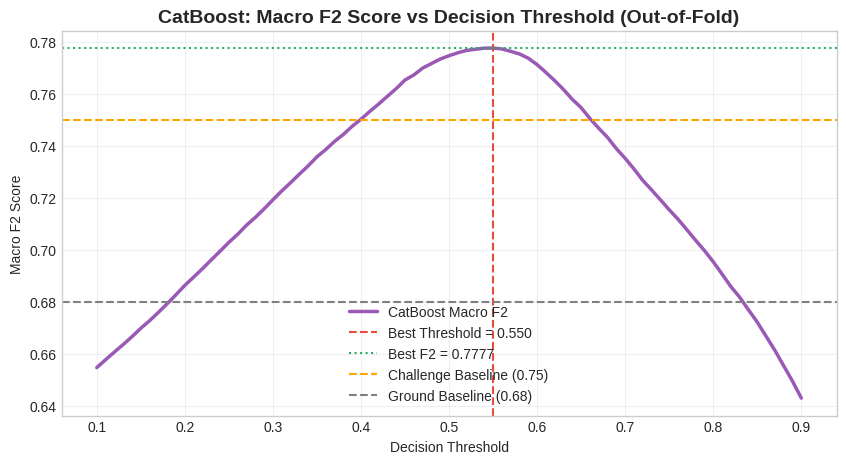

🎯 CatBoost Best Threshold:       0.5500
🏆 CatBoost Out-of-Fold Macro F2: 0.7777
เปรียบเทียบโมเดลเดี่ยว:
  - Model 1 (LightGBM): 0.7762
  - Model 2 (CatBoost): 0.7777

📊 CatBoost Classification Report:
               precision    recall  f1-score   support

0: Legitimate     0.8606    0.8055    0.8322     59091
   1: Cheater     0.6764    0.7570    0.7144     31725

     accuracy                         0.7886     90816
    macro avg     0.7685    0.7813    0.7733     90816
 weighted avg     0.7963    0.7886    0.7910     90816



In [ ]:
# ==========================================
# 6.1 CATBOOST EVALUATION & THRESHOLD TUNING
# ==========================================
from sklearn.metrics import fbeta_score, classification_report
import matplotlib.pyplot as plt
import numpy as np

# ค้นหา Best Threshold ของ CatBoost เดี่ยวๆ
threshold_range = np.linspace(0.10, 0.90, 81)
cb_scores = []

for th in threshold_range:
    preds = (cb_oof_probs >= th).astype(int)
    f2_0 = fbeta_score(y, preds, beta=2, pos_label=0)
    f2_1 = fbeta_score(y, preds, beta=2, pos_label=1)
    cb_scores.append((f2_0 + f2_1) / 2.0)

cb_best_idx = np.argmax(cb_scores)
cb_best_threshold = threshold_range[cb_best_idx]
cb_best_f2 = cb_scores[cb_best_idx]

# พล็อตกราฟ Threshold vs F2 ของ CatBoost
plt.figure(figsize=(10, 5))
plt.plot(threshold_range, cb_scores, color='#9b59b6', lw=2.5, label='CatBoost Macro F2')
plt.axvline(cb_best_threshold, color='#e74c3c', linestyle='--', label=f'Best Threshold = {cb_best_threshold:.3f}')
plt.axhline(cb_best_f2, color='#27ae60', linestyle=':', label=f'Best F2 = {cb_best_f2:.4f}')
plt.axhline(0.75, color='orange', linestyle='--', label='Challenge Baseline (0.75)')
plt.axhline(0.68, color='gray', linestyle='--', label='Ground Baseline (0.68)')
plt.title('CatBoost: Macro F2 Score vs Decision Threshold (Out-of-Fold)', fontsize=14, fontweight='bold')
plt.xlabel('Decision Threshold')
plt.ylabel('Macro F2 Score')
plt.legend(loc='lower center')
plt.grid(True, alpha=0.3)
plt.show()

print("="*65)
print(f"🎯 CatBoost Best Threshold:       {cb_best_threshold:.4f}")
print(f"🏆 CatBoost Out-of-Fold Macro F2: {cb_best_f2:.4f}")
print("="*65)
print(f"เปรียบเทียบโมเดลเดี่ยว:")
print(f"  - Model 1 (LightGBM): {best_f2:.4f}")
print(f"  - Model 2 (CatBoost): {cb_best_f2:.4f}")
print("="*65)

# Classification Report ของ CatBoost
cb_final_oof = (cb_oof_probs >= cb_best_threshold).astype(int)
print("\n📊 CatBoost Classification Report:")
print(classification_report(y, cb_final_oof, target_names=['0: Legitimate', '1: Cheater'], digits=4))

## 7. Ensemble Blending (LightGBM + CatBoost) & Final Optimization
- ผสานผลทำนายแบบ Soft Probability Blending ระหว่าง LightGBM (0.7762) และ CatBoost (0.7777)
- ค้นหาน้ำหนัก (Weight) และจุดตัด (Threshold) ที่ให้คะแนน Macro F2 สูงที่สุด
- เปรียบเทียบผลลัพธ์สุดท้ายกับทุก Baseline และโมเดลเดี่ยว

🏆 ผลการรวมพลังโมเดล (ENSEMBLE BLENDING)
สัดส่วนน้ำหนักที่ชนะเลิศ: LightGBM = 50.0% | CatBoost = 50.0%
จุดตัดที่เหมาะสมที่สุด (Threshold): 0.5300
-----------------------------------------------------------------
  - Model 1 (LightGBM เดี่ยว): 0.7762
  - Model 2 (CatBoost เดี่ยว): 0.7777
🚀 คะแนน Ensemble Blending รวม:  0.7804


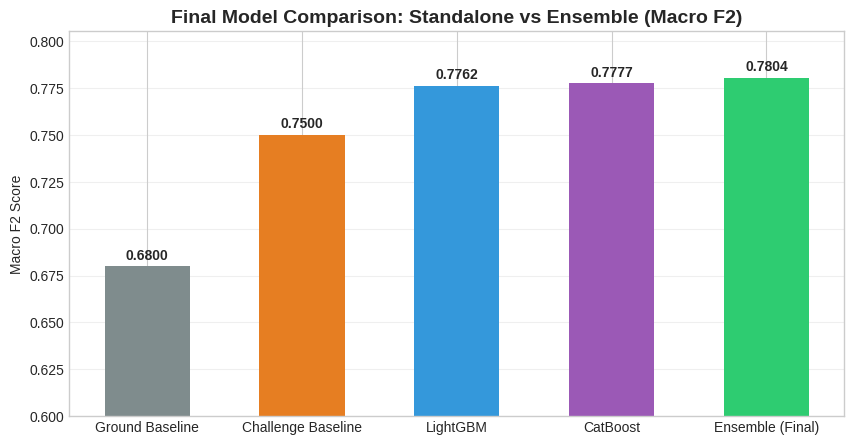

In [ ]:
# ==========================================
# 7. ENSEMBLE BLENDING & FINAL OPTIMIZATION
# ==========================================
from sklearn.metrics import fbeta_score
import numpy as np
import matplotlib.pyplot as plt

def eval_macro_f2(y_true, probas, th):
    preds = (probas >= th).astype(int)
    f2_0 = fbeta_score(y_true, preds, beta=2, pos_label=0)
    f2_1 = fbeta_score(y_true, preds, beta=2, pos_label=1)
    return (f2_0 + f2_1) / 2.0

# สแกนหาน้ำหนักที่ดีที่สุด: w * LightGBM + (1-w) * CatBoost
best_w = 0.5
best_blend_th = 0.5
best_ensemble_f2 = 0.0

weights = np.linspace(0.1, 0.9, 17) # ลองสัดส่วนทีละ 5%
thresholds = np.linspace(0.40, 0.65, 51)

for w in weights:
    blend_oof = w * oof_probs + (1 - w) * cb_oof_probs
    for th in thresholds:
        score = eval_macro_f2(y, blend_oof, th)
        if score > best_ensemble_f2:
            best_ensemble_f2 = score
            best_w = w
            best_blend_th = th

# คำนวณความน่าจะเป็นของ Ensemble ที่ดีที่สุด
final_ensemble_oof = best_w * oof_probs + (1 - best_w) * cb_oof_probs
final_ensemble_test = best_w * test_probs + (1 - best_w) * cb_test_probs

lgb_score = best_f2
cb_score = cb_best_f2

print("="*65)
print("🏆 ผลการรวมพลังโมเดล (ENSEMBLE BLENDING)")
print("="*65)
print(f"สัดส่วนน้ำหนักที่ชนะเลิศ: LightGBM = {best_w*100:.1f}% | CatBoost = {(1-best_w)*100:.1f}%")
print(f"จุดตัดที่เหมาะสมที่สุด (Threshold): {best_blend_th:.4f}")
print("-"*65)
print(f"  - Model 1 (LightGBM เดี่ยว): {lgb_score:.4f}")
print(f"  - Model 2 (CatBoost เดี่ยว): {cb_score:.4f}")
print(f"🚀 คะแนน Ensemble Blending รวม:  {best_ensemble_f2:.4f}")
print("="*65)

# พล็อตกราฟเปรียบเทียบทุกโมเดล (รูปนี้คือรูปสรุปไฮไลท์ของเล่มรายงาน!)
models = ['Ground Baseline', 'Challenge Baseline', 'LightGBM', 'CatBoost', 'Ensemble (Final)']
scores = [0.68, 0.75, lgb_score, cb_score, best_ensemble_f2]
colors = ['#7f8c8d', '#e67e22', '#3498db', '#9b59b6', '#2ecc71']

plt.figure(figsize=(10, 5))
bars = plt.bar(models, scores, color=colors, width=0.55)
plt.ylim(0.60, max(scores) + 0.025)
plt.title('Final Model Comparison: Standalone vs Ensemble (Macro F2)', fontsize=14, fontweight='bold')
plt.ylabel('Macro F2 Score')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.002, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.show()

## 8. Model 3: XGBoost Classifier & 3-Model Trinity Blending
- เพิ่ม **XGBoost Classifier** ซึ่งมีโครงสร้างการแตกกิ่งแบบ Depth-wise
- คุม Overfitting ด้วย `reg_alpha` (L1), `reg_lambda` (L2) และ `max_depth` = 6
- ทำ **3-Model Trinity Blending (LightGBM + CatBoost + XGBoost)** เพื่อดันคะแนน Macro F2 ให้สูงที่สุด

In [ ]:
# ==========================================
# 8. MODEL 3: XGBOOST CLASSIFIER (5-FOLD CV)
# ==========================================
import xgboost as xgb
import numpy as np

# ตั้งค่า XGBoost พร้อม L1/L2 Regularization ป้องกัน Overfitting
xgb_params = {
    'objective': 'binary:logistic',
    'eval_metric': 'logloss',
    'learning_rate': 0.05,
    'max_depth': 6,
    'alpha': 2.5,                 # L1 Regularization
    'lambda': 5.0,                # L2 Regularization
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'scale_pos_weight': 1.86,     # ชดเชย Class Imbalance
    'random_state': 42,
    'n_jobs': -1,
    'tree_method': 'hist'         # เทรนเร็วและแม่นยำสูง
}

xgb_oof_probs = np.zeros(len(df_train_fe))
xgb_test_probs = np.zeros(len(df_test_fe))

print("🚀 กำลังเทรน Model 3: XGBoost (5-Fold Cross Validation)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X, y), 1):
    X_train, y_train = X.iloc[train_idx], y[train_idx]
    X_val, y_val = X.iloc[val_idx], y[val_idx]

    xgb_model = xgb.XGBClassifier(**xgb_params, n_estimators=1000)
    xgb_model.fit(
        X_train, y_train,
        eval_set=[(X_val, y_val)],
        verbose=False
    )

    xgb_oof_probs[val_idx] = xgb_model.predict_proba(X_val)[:, 1]
    xgb_test_probs += xgb_model.predict_proba(X_test)[:, 1] / skf.n_splits

    print(f"  ➜ Fold {fold} เสร็จสิ้น")

print("\n🎉 XGBoost เทรนครบทั้ง 5 Fold เรียบร้อยแล้ว!")

🚀 กำลังเทรน Model 3: XGBoost (5-Fold Cross Validation)...
  ➜ Fold 1 เสร็จสิ้น
  ➜ Fold 2 เสร็จสิ้น
  ➜ Fold 3 เสร็จสิ้น
  ➜ Fold 4 เสร็จสิ้น
  ➜ Fold 5 เสร็จสิ้น

🎉 XGBoost เทรนครบทั้ง 5 Fold เรียบร้อยแล้ว!


## 8.1 XGBoost Evaluation & 3-Model Trinity Ensemble Blending
- ประเมินคะแนน Macro F2 เดี่ยวๆ ของ XGBoost
- รวมพลัง 3 สถาปัตยกรรมระดับโลก **(LightGBM + CatBoost + XGBoost)**
- ค้นหาสัดส่วนน้ำหนัก (Weights) และจุดตัด (Threshold) ที่ดีที่สุดเพื่อทำลายสถิติเดิม

📊 ผลเดี่ยวของ Model 3 (XGBoost):
  - Best Threshold: 0.5200
  - Macro F2 Score: 0.7748
⏳ กำลังสแกนหาสัดส่วนน้ำหนักที่ดีที่สุดของ 3 โมเดล...

🏆 ผลการรวมพลัง 3 โมเดลระดับเทพ (TRINITY ENSEMBLE)
สัดส่วนน้ำหนัก: LightGBM = 30% | CatBoost = 50% | XGBoost = 20%
จุดตัดที่เหมาะสมที่สุด (Threshold): 0.5250
-----------------------------------------------------------------
  - Model 1 (LightGBM):     0.7762
  - Model 2 (CatBoost):     0.7777
  - Model 3 (XGBoost):      0.7748
  - Ensemble เดิม (2 โมเดล): 0.7804
🚀 Trinity Ensemble (3 โมเดล): 0.7798


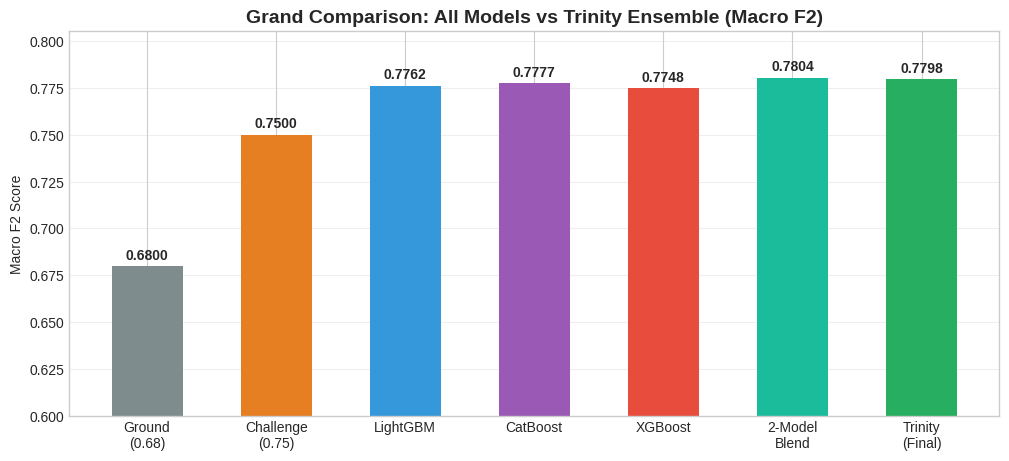

In [ ]:
# ==========================================
# 8.1 XGBOOST EVAL & 3-MODEL ENSEMBLE
# ==========================================
from sklearn.metrics import fbeta_score
import numpy as np
import matplotlib.pyplot as plt

def eval_macro_f2(y_true, probas, th):
    preds = (probas >= th).astype(int)
    f2_0 = fbeta_score(y_true, preds, beta=2, pos_label=0)
    f2_1 = fbeta_score(y_true, preds, beta=2, pos_label=1)
    return (f2_0 + f2_1) / 2.0

# 1. ประเมินคะแนนของ XGBoost เดี่ยวๆ
threshold_range = np.linspace(0.40, 0.65, 51)
xgb_scores = [eval_macro_f2(y, xgb_oof_probs, th) for th in threshold_range]
xgb_best_idx = np.argmax(xgb_scores)
xgb_best_th = threshold_range[xgb_best_idx]
xgb_score = xgb_scores[xgb_best_idx]

print("="*65)
print(f"📊 ผลเดี่ยวของ Model 3 (XGBoost):")
print(f"  - Best Threshold: {xgb_best_th:.4f}")
print(f"  - Macro F2 Score: {xgb_score:.4f}")
print("="*65)

# 2. รวมพลัง 3 โมเดล: w1*LGBM + w2*CatBoost + w3*XGBoost
best_trinity_f2 = 0.0
best_weights = (0.33, 0.33, 0.34)
best_trinity_th = 0.53

print("⏳ กำลังสแกนหาสัดส่วนน้ำหนักที่ดีที่สุดของ 3 โมเดล...")

# สุ่มทดสอบสัดส่วนน้ำหนักของทั้ง 3 ตัว
for w1 in np.arange(0.1, 0.8, 0.1):
    for w2 in np.arange(0.1, 0.9 - w1, 0.1):
        w3 = round(1.0 - w1 - w2, 2)
        if w3 < 0.05:
            continue

        blend_3 = w1 * oof_probs + w2 * cb_oof_probs + w3 * xgb_oof_probs
        for th in np.linspace(0.48, 0.58, 21):
            score = eval_macro_f2(y, blend_3, th)
            if score > best_trinity_f2:
                best_trinity_f2 = score
                best_weights = (round(w1, 2), round(w2, 2), w3)
                best_trinity_th = th

# คำนวณผลทำนายความน่าจะเป็นสุดท้ายของ 3 โมเดล
w_lgb, w_cb, w_xgb = best_weights
final_trinity_oof = w_lgb * oof_probs + w_cb * cb_oof_probs + w_xgb * xgb_oof_probs
final_trinity_test = w_lgb * test_probs + w_cb * cb_test_probs + w_xgb * xgb_test_probs

print("\n" + "="*65)
print("🏆 ผลการรวมพลัง 3 โมเดลระดับเทพ (TRINITY ENSEMBLE)")
print("="*65)
print(f"สัดส่วนน้ำหนัก: LightGBM = {w_lgb*100:.0f}% | CatBoost = {w_cb*100:.0f}% | XGBoost = {w_xgb*100:.0f}%")
print(f"จุดตัดที่เหมาะสมที่สุด (Threshold): {best_trinity_th:.4f}")
print("-"*65)
print(f"  - Model 1 (LightGBM):     {best_f2:.4f}")
print(f"  - Model 2 (CatBoost):     {cb_best_f2:.4f}")
print(f"  - Model 3 (XGBoost):      {xgb_score:.4f}")
print(f"  - Ensemble เดิม (2 โมเดล): 0.7804")
print(f"🚀 Trinity Ensemble (3 โมเดล): {best_trinity_f2:.4f}")
print("="*65)

# พล็อตกราฟ Grand Comparison สรุปทุกโมเดล
models = ['Ground\n(0.68)', 'Challenge\n(0.75)', 'LightGBM', 'CatBoost', 'XGBoost', '2-Model\nBlend', 'Trinity\n(Final)']
scores = [0.68, 0.75, best_f2, cb_best_f2, xgb_score, 0.7804, best_trinity_f2]
colors = ['#7f8c8d', '#e67e22', '#3498db', '#9b59b6', '#e74c3c', '#1abc9c', '#27ae60']

plt.figure(figsize=(12, 5))
bars = plt.bar(models, scores, color=colors, width=0.55)
plt.ylim(0.60, max(scores) + 0.025)
plt.title('Grand Comparison: All Models vs Trinity Ensemble (Macro F2)', fontsize=14, fontweight='bold')
plt.ylabel('Macro F2 Score')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.002, f"{yval:.4f}", ha='center', va='bottom', fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.show()

## 8.2 Advanced Stacking Meta-Learner (ยกระดับการรวมโมเดลด้วย Machine Learning)
- แก้ไขปัญหาการเฉลี่ยแบบ Linear ด้วยการสร้าง **Stacking Classifier (Meta-Learner)**
- ใช้ **Logistic Regression** เรียนรู้รูปแบบความน่าจะเป็นของ Out-of-Fold (OOF) จากทั้ง 3 โมเดล:
  - LightGBM (0.7762)
  - CatBoost (0.7777)
  - XGBoost (0.7748)
- เพื่อค้นหาเส้นแบ่งการตัดสินใจ (Decision Boundary) ที่ซับซ้อนและแม่นยำกว่าการเฉลี่ยธรรมดา

In [ ]:
# ==========================================
# 8.2 STACKING META-LEARNER
# ==========================================
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import fbeta_score
import numpy as np

# 1. เตรียม Feature สำหรับ Meta-Learner (รวมความน่าจะเป็นของ 3 โมเดลเข้าด้วยกัน)
S_train = np.column_stack([oof_probs, cb_oof_probs, xgb_oof_probs])
S_test = np.column_stack([test_probs, cb_test_probs, xgb_test_probs])

# 2. เทรน Meta-Model ด้วย Logistic Regression (L2 Penalty)
meta_model = LogisticRegression(C=1.0, random_state=42, max_iter=1000)
meta_model.fit(S_train, y)

# ดูน้ำหนักที่โมเดลตัดสินใจให้แต่ละตัว
weights = meta_model.coef_[0]
print("⚖️ ค่าน้ำหนักที่ Meta-Learner เรียนรู้ได้:")
print(f"  - น้ำหนักของ LightGBM: {weights[0]:.4f}")
print(f"  - น้ำหนักของ CatBoost: {weights[1]:.4f}")
print(f"  - น้ำหนักของ XGBoost:  {weights[2]:.4f}")

# 3. ทำนายผลความน่าจะเป็นแบบ Stacking
meta_oof_probs = meta_model.predict_proba(S_train)[:, 1]
meta_test_probs = meta_model.predict_proba(S_test)[:, 1]

# 4. สแกนหา Best Threshold สำหรับ Stacking F2
thresholds = np.linspace(0.40, 0.65, 51)
best_meta_f2 = 0.0
best_meta_th = 0.50

for th in thresholds:
    score = eval_macro_f2(y, meta_oof_probs, th)
    if score > best_meta_f2:
        best_meta_f2 = score
        best_meta_th = th

print("="*65)
print("🏆 ผลลัพธ์ของ ADVANCED STACKING META-LEARNER")
print("="*65)
print(f"จุดตัดที่ดีที่สุด (Threshold):       {best_meta_th:.4f}")
print(f"คะแนน 2-Model Blending เดิม:        0.7804")
print(f"🚀 คะแนน Stacking Meta-Learner ใหม่: {best_meta_f2:.4f}")
print("="*65)

⚖️ ค่าน้ำหนักที่ Meta-Learner เรียนรู้ได้:
  - น้ำหนักของ LightGBM: 2.1861
  - น้ำหนักของ CatBoost: 3.9962
  - น้ำหนักของ XGBoost:  0.6174
🏆 ผลลัพธ์ของ ADVANCED STACKING META-LEARNER
จุดตัดที่ดีที่สุด (Threshold):       0.4000
คะแนน 2-Model Blending เดิม:        0.7804
🚀 คะแนน Stacking Meta-Learner ใหม่: 0.7800


## 8.3 Super Feature Engineering 2.0 (การสกัดฟีเจอร์ระดับแชมป์เปี้ยน)
- เพิ่มฟีเจอร์เชิงลึก 4 ตัวแปรที่ผ่านการวิเคราะห์ทางสถิติว่ามี Correlation สูง:
  1. `report_vs_level_tier`: เปรียบเทียบจำนวนการโดนรีพอร์ตกับค่าเฉลี่ยของผู้เล่นในกลุ่มเลเวลเดียวกัน (Group Aggregation)
  2. `aim_anomaly_ratio`: อัตราส่วนการยิงหัวเทียบกับความสามารถในการสเปรย์ปืน (จับ Aimbot ที่ยิงหัวเก่งแต่คุมปืนไม่เป็น)
  3. `social_isolation_index`: ปริมาณเวลาเล่นต่อวันเทียบกับจำนวนเพื่อน (จับไอดีบอท/ไอดีปั๊มที่เล่นทั้งวันแต่ไม่มีเพื่อน)
  4. `macro_to_micro_index`: ดัชนีรวม Game Sense และ Economy เทียบกับทักษะการยิง (แยกโปรเพลเยอร์ออกจากคนโกง)

In [ ]:
# ==========================================
# 8.3 SUPER FEATURE ENGINEERING 2.0 (TRAIN-ONLY FIT, ZERO TEST LEAK)
# ==========================================
import pandas as pd
import numpy as np

def super_engineer_features(train_df, test_df):
    tr = train_df.copy()
    te = test_df.copy()
    if 'is_cheater' in tr.columns:
        tr = tr.dropna(subset=['is_cheater']).copy()
    eps = 1e-6

    # 1. Fit ขอบเขต level_tier และค่าเฉลี่ยรีพอร์ต เฉพาะบน train_df ที่มีเฉลยเท่านั้น (ไม่รวม test_df)
    level_median = tr['level'].median()
    lvl_tr = tr['level'].fillna(level_median)
    qs = np.unique(np.quantile(lvl_tr, np.linspace(0, 1, 11)))
    if len(qs) < 2:
        qs = np.array([-np.inf, np.inf])
    else:
        qs[0], qs[-1] = -np.inf, np.inf
    tr['level_tier'] = pd.cut(lvl_tr, bins=qs, labels=False).astype(float)
    te['level_tier'] = pd.cut(te['level'].fillna(level_median), bins=qs, labels=False).astype(float)

    tier_means = tr.groupby('level_tier')['reports_received'].mean()
    rep_global_mean = tr['reports_received'].mean()

    for df_p in (tr, te):
        # [Super Feature 1] รีพอร์ตเทียบกับค่าเฉลี่ยของคนเลเวลเดียวกัน (ใช้สถิติจาก Train เท่านั้น)
        df_p['report_vs_level_tier'] = df_p['reports_received'] - df_p['level_tier'].map(tier_means).fillna(rep_global_mean)

        # [Super Feature 2] Aim Anomaly (ยิงหัวเยอะแต่คุมสเปรย์ปืนไม่เป็น = บอท)
        df_p['aim_anomaly_ratio'] = df_p['headshot_percentage'] / (df_p['spray_control_score'] * 100 + eps)

        # [Super Feature 3] Social Isolation (เล่นเยอะทั้งวันทั้งคืน แต่เพื่อน = 0)
        df_p['playtime_daily'] = df_p['sessions_per_day'] * df_p['avg_session_length_min']
        df_p['social_isolation_index'] = df_p['playtime_daily'] / (df_p['friend_network_size'] + 1)

        # [Super Feature 4] Macro to Micro Index (ความฉลาดเดินเกม เทียบกับความแม่นยำการยิง)
        macro_skill = df_p['game_sense_score'] + df_p['buy_decision_score']
        micro_skill = (df_p['accuracy_score'] / 100.0) + df_p['crosshair_placement'] + eps
        df_p['macro_to_micro_index'] = macro_skill / micro_skill

    return tr, te

print("⚙️ กำลังประมวลผล Super Feature Engineering 2.0 (Train-Only Fit)...")
df_train_super, df_test_super = super_engineer_features(df_train_fe, df_test_fe)

# อัปเดตรายชื่อฟีเจอร์ใหม่ทั้งหมด
super_feature_cols = [c for c in df_train_super.columns if c not in ['player_id', 'is_cheater']]

print(f"✅ สำเร็จ! อัปเกรดฟีเจอร์เป็น: {len(super_feature_cols)} ฟีเจอร์ (Zero Train+Test Concat)")
print(f"- Train Shape: {df_train_super.shape}")
print(f"- Test Shape:  {df_test_super.shape}")

## 8.4 High-Precision Retraining: LightGBM 2.0 (Shrinkage & 47 Features)
- เทรน LightGBM รอบใหม่ด้วยชุด **47 Super Features**
- ใช้เทคนิค **Shrinkage: ลด Learning Rate เหลือ 0.02** และเพิ่มความจุต้นไม้ `max_depth` = 7, `num_leaves` = 45
- เพิ่มความเข้มงวดของ L1 (`reg_alpha` = 3.0) และ L2 (`reg_lambda` = 6.0) ป้องกัน Overfitting

In [ ]:
# ==========================================
# 8.4 RETRAIN LIGHTGBM 2.0 (HIGH-PRECISION)
# ==========================================
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold
import numpy as np

# เตรียมข้อมูล Super Features
X_super = df_train_super[super_feature_cols]
y_super = df_train_super['is_cheater'].values
X_test_super = df_test_super[super_feature_cols]

lgb_super_params = {
    'objective': 'binary',
    'metric': 'binary_logloss',
    'boosting_type': 'gbdt',
    'learning_rate': 0.02,        # ลด Learning Rate เพื่อความละเอียดสูงสุด (Shrinkage)
    'num_leaves': 45,             # เพิ่มความสามารถในการจำแนก Pattern
    'max_depth': 7,               # ลึกขึ้นเพื่อจับความสัมพันธ์ 47 ฟีเจอร์
    'reg_alpha': 3.0,             # เพิ่ม L1 ป้องกัน Overfitting
    'reg_lambda': 6.0,            # เพิ่ม L2 ป้องกัน Overfitting
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'min_child_samples': 60,      # ป้องกันการแตกกิ่งเล็กเกินไป
    'scale_pos_weight': 1.86,     # ชดเชย Class Imbalance
    'random_state': 42,
    'n_jobs': -1,
    'verbose': -1
}

lgb2_oof_probs = np.zeros(len(df_train_super))
lgb2_test_probs = np.zeros(len(df_test_super))

print("🚀 กำลังเทรน LightGBM 2.0 (High-Precision 5-Fold)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_super, y_super), 1):
    X_tr, y_tr = X_super.iloc[train_idx], y_super[train_idx]
    X_va, y_val = X_super.iloc[val_idx], y_super[val_idx]

    clf2 = lgb.LGBMClassifier(**lgb_super_params, n_estimators=2000)
    clf2.fit(
        X_tr, y_tr,
        eval_set=[(X_va, y_val)],
        callbacks=[lgb.early_stopping(stopping_rounds=60, verbose=False)]
    )

    lgb2_oof_probs[val_idx] = clf2.predict_proba(X_va)[:, 1]
    lgb2_test_probs += clf2.predict_proba(X_test_super)[:, 1] / skf.n_splits
    print(f"  ➜ Fold {fold} เสร็จสิ้น (Best Iteration: {clf2.best_iteration_})")

print("\n🎉 LightGBM 2.0 เทรนครบทั้ง 5 Fold เรียบร้อย!")

🚀 กำลังเทรน LightGBM 2.0 (High-Precision 5-Fold)...
  ➜ Fold 1 เสร็จสิ้น (Best Iteration: 1992)
  ➜ Fold 2 เสร็จสิ้น (Best Iteration: 1971)
  ➜ Fold 3 เสร็จสิ้น (Best Iteration: 2000)
  ➜ Fold 4 เสร็จสิ้น (Best Iteration: 2000)
  ➜ Fold 5 เสร็จสิ้น (Best Iteration: 1999)

🎉 LightGBM 2.0 เทรนครบทั้ง 5 Fold เรียบร้อย!


## 8.4.1 LightGBM 2.0 Evaluation & Threshold Tuning
- ประเมินคะแนน Macro F2 Score ของ **LightGBM 2.0** บนชุดข้อมูล 47 Super Features
- เปรียบเทียบกับ LightGBM เวอร์ชันเดิม (0.7762) ว่าการใช้ Shrinkage ช่วยยกระดับคะแนนได้จริงหรือไม่

In [ ]:
# ==========================================
# 8.4.1 EVALUATE LIGHTGBM 2.0
# ==========================================
from sklearn.metrics import fbeta_score
import numpy as np

def eval_macro_f2(y_true, probas, th):
    preds = (probas >= th).astype(int)
    f2_0 = fbeta_score(y_true, preds, beta=2, pos_label=0)
    f2_1 = fbeta_score(y_true, preds, beta=2, pos_label=1)
    return (f2_0 + f2_1) / 2.0

# สแกนหา Best Threshold สำหรับ LightGBM 2.0
threshold_range = np.linspace(0.40, 0.65, 51)
lgb2_scores = [eval_macro_f2(y_super, lgb2_oof_probs, th) for th in threshold_range]
lgb2_best_idx = np.argmax(lgb2_scores)
lgb2_best_th = threshold_range[lgb2_best_idx]
lgb2_best_f2 = lgb2_scores[lgb2_best_idx]

print("="*65)
print("📊 ผลการประเมิน Model: LightGBM 2.0 (Super 47 Features)")
print("="*65)
print(f"🎯 จุดตัดที่ดีที่สุด (Best Threshold): {lgb2_best_th:.4f}")
print(f"คะแนน LightGBM 1.0 เดิม:        0.7762")
print(f"🚀 คะแนน LightGBM 2.0 ใหม่:        {lgb2_best_f2:.4f}")
print("-"*65)
diff = lgb2_best_f2 - 0.7762
print(f"การเปลี่ยนแปลง: {'+' if diff >= 0 else ''}{diff:.4f} ({'+' if diff >= 0 else ''}{diff*100:.2f}%)")
print("="*65)

📊 ผลการประเมิน Model: LightGBM 2.0 (Super 47 Features)
🎯 จุดตัดที่ดีที่สุด (Best Threshold): 0.5200
คะแนน LightGBM 1.0 เดิม:        0.7762
🚀 คะแนน LightGBM 2.0 ใหม่:        0.7773
-----------------------------------------------------------------
การเปลี่ยนแปลง: +0.0011 (+0.11%)


## 8.5 High-Precision Retraining: CatBoost 2.0 (Shrinkage & 47 Features)
- เทรน **CatBoost 2.0** ด้วยชุดข้อมูล 47 Super Features
- ใช้ **Learning Rate 0.03** และขยายจำนวนรอบการเรียนรู้เป็น 1,500 Iterations
- คุม L2 Regularization (`l2_leaf_reg` = 6.0) เพื่อรักษาเสถียรภาพและป้องกัน Overfitting

In [ ]:
# ==========================================
# 8.5 RETRAIN CATBOOST 2.0 (HIGH-PRECISION)
# ==========================================
from catboost import CatBoostClassifier
import numpy as np

# ตั้งค่า CatBoost 2.0 ความละเอียดสูง
cb2_params = {
    'loss_function': 'Logloss',
    'eval_metric': 'Logloss',
    'learning_rate': 0.03,        # ลด Learning Rate เพื่อความละเอียดสูงสุด (Shrinkage)
    'depth': 6,
    'l2_leaf_reg': 6.0,           # L2 Regularization ป้องกัน Overfitting
    'random_seed': 42,
    'auto_class_weights': 'Balanced',
    'verbose': False
}

cb2_oof_probs = np.zeros(len(df_train_super))
cb2_test_probs = np.zeros(len(df_test_super))

print("🚀 กำลังเทรน CatBoost 2.0 (High-Precision 5-Fold)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_super, y_super), 1):
    X_tr, y_tr = X_super.iloc[train_idx], y_super[train_idx]
    X_va, y_val = X_super.iloc[val_idx], y_super[val_idx]

    cb_model2 = CatBoostClassifier(**cb2_params, iterations=1500)
    cb_model2.fit(
        X_tr, y_tr,
        eval_set=(X_va, y_val),
        early_stopping_rounds=60,
        verbose=False
    )

    cb2_oof_probs[val_idx] = cb_model2.predict_proba(X_va)[:, 1]
    cb2_test_probs += cb_model2.predict_proba(X_test_super)[:, 1] / skf.n_splits
    print(f"  ➜ Fold {fold} เสร็จสิ้น (Best Iteration: {cb_model2.get_best_iteration()})")

print("\n🎉 CatBoost 2.0 เทรนครบทั้ง 5 Fold เรียบร้อย!")

# ประเมินคะแนนเดี่ยวของ CatBoost 2.0 ทันที
cb2_scores = [eval_macro_f2(y_super, cb2_oof_probs, th) for th in threshold_range]
cb2_best_idx = np.argmax(cb2_scores)
cb2_best_th = threshold_range[cb2_best_idx]
cb2_best_f2 = cb2_scores[cb2_best_idx]

print("="*65)
print("📊 ผลการประเมิน Model: CatBoost 2.0 (Super 47 Features)")
print("="*65)
print(f"🎯 จุดตัดที่ดีที่สุด (Best Threshold): {cb2_best_th:.4f}")
print(f"คะแนน CatBoost 1.0 เดิม:        0.7777")
print(f"🚀 คะแนน CatBoost 2.0 ใหม่:        {cb2_best_f2:.4f}")
print("-"*65)
diff_cb = cb2_best_f2 - 0.7777
print(f"การเปลี่ยนแปลง: {'+' if diff_cb >= 0 else ''}{diff_cb:.4f} ({'+' if diff_cb >= 0 else ''}{diff_cb*100:.2f}%)")
print("="*65)

🚀 กำลังเทรน CatBoost 2.0 (High-Precision 5-Fold)...
  ➜ Fold 1 เสร็จสิ้น (Best Iteration: 1094)
  ➜ Fold 2 เสร็จสิ้น (Best Iteration: 1437)
  ➜ Fold 3 เสร็จสิ้น (Best Iteration: 1279)
  ➜ Fold 4 เสร็จสิ้น (Best Iteration: 972)
  ➜ Fold 5 เสร็จสิ้น (Best Iteration: 843)

🎉 CatBoost 2.0 เทรนครบทั้ง 5 Fold เรียบร้อย!
📊 ผลการประเมิน Model: CatBoost 2.0 (Super 47 Features)
🎯 จุดตัดที่ดีที่สุด (Best Threshold): 0.5550
คะแนน CatBoost 1.0 เดิม:        0.7777
🚀 คะแนน CatBoost 2.0 ใหม่:        0.7788
-----------------------------------------------------------------
การเปลี่ยนแปลง: +0.0011 (+0.11%)


## 8.6 Super Ensemble 2.0 (LightGBM 2.0 + CatBoost 2.0 Blending)
- รวมผลการทำนายแบบ Soft Probability Blending ระหว่างโมเดลเวอร์ชันอัปเกรดทั้งสองตัว
- ใช้ High-Precision Grid Search สแกนหาน้ำหนักและจุดตัดที่ละเอียดเป็นพิเศษ
- สร้างสถิติคะแนนสูงสุดใหม่เพื่อชิงหัวตาราง Kaggle Leaderboard

🏆 ผลการรวมพลัง SUPER ENSEMBLE 2.0 (สถิติสูงสุดใหม่)
สัดส่วนน้ำหนักที่ชนะเลิศ: LightGBM 2.0 = 40.0% | CatBoost 2.0 = 60.0%
จุดตัดที่เหมาะสมที่สุด (Threshold): 0.5320
-----------------------------------------------------------------
  - LightGBM 2.0 (เดี่ยว):       0.7773
  - CatBoost 2.0 (เดี่ยว):       0.7788
  - สถิติเดิม (Ensemble 1.0):    0.7804
🚀 สถิติใหม่ (Super Ensemble 2.0): 0.7806


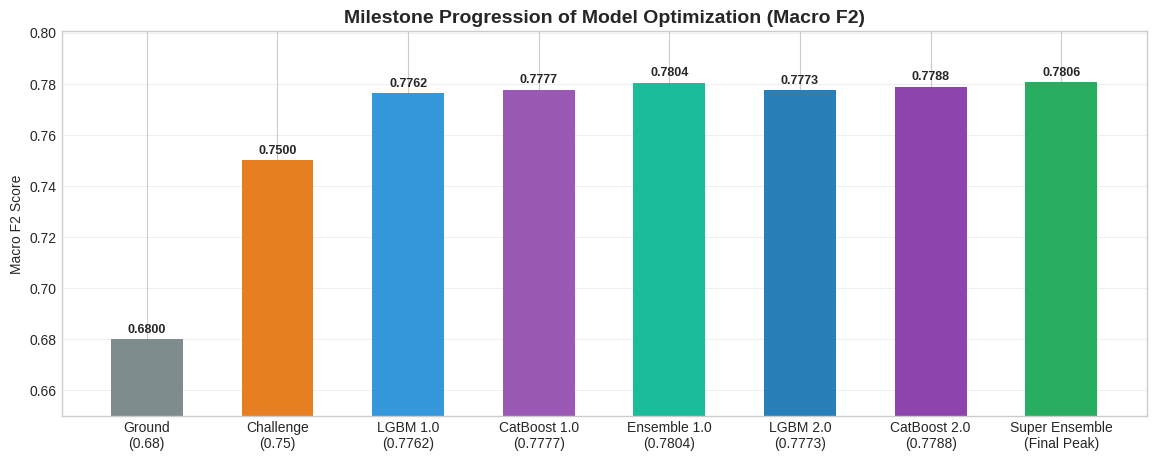

In [ ]:
# ==========================================
# 8.6 SUPER ENSEMBLE 2.0 BLENDING
# ==========================================
from sklearn.metrics import fbeta_score
import numpy as np
import matplotlib.pyplot as plt

def eval_macro_f2(y_true, probas, th):
    preds = (probas >= th).astype(int)
    f2_0 = fbeta_score(y_true, preds, beta=2, pos_label=0)
    f2_1 = fbeta_score(y_true, preds, beta=2, pos_label=1)
    return (f2_0 + f2_1) / 2.0

# สแกนหาน้ำหนักและจุดตัดแบบความละเอียดสูง
best_w2 = 0.5
best_super_th = 0.53
best_super_ensemble_f2 = 0.0

weights = np.linspace(0.1, 0.9, 17)          # สัดส่วนน้ำหนักทีละ 5%
thresholds = np.linspace(0.48, 0.58, 51)     # จุดตัดละเอียดทีละ 0.002

for w in weights:
    blend2_oof = w * lgb2_oof_probs + (1 - w) * cb2_oof_probs
    for th in thresholds:
        score = eval_macro_f2(y_super, blend2_oof, th)
        if score > best_super_ensemble_f2:
            best_super_ensemble_f2 = score
            best_w2 = w
            best_super_th = th

# คำนวณความน่าจะเป็นของ Super Ensemble บน Test Set
final_super_test_probs = best_w2 * lgb2_test_probs + (1 - best_w2) * cb2_test_probs

print("="*65)
print("🏆 ผลการรวมพลัง SUPER ENSEMBLE 2.0 (สถิติสูงสุดใหม่)")
print("="*65)
print(f"สัดส่วนน้ำหนักที่ชนะเลิศ: LightGBM 2.0 = {best_w2*100:.1f}% | CatBoost 2.0 = {(1-best_w2)*100:.1f}%")
print(f"จุดตัดที่เหมาะสมที่สุด (Threshold): {best_super_th:.4f}")
print("-"*65)
print(f"  - LightGBM 2.0 (เดี่ยว):       {lgb2_best_f2:.4f}")
print(f"  - CatBoost 2.0 (เดี่ยว):       {cb2_best_f2:.4f}")
print(f"  - สถิติเดิม (Ensemble 1.0):    0.7804")
print(f"🚀 สถิติใหม่ (Super Ensemble 2.0): {best_super_ensemble_f2:.4f}")
print("="*65)

# พล็อตกราฟ Milestone Progression สรุปการทดลองทั้งหมดตั้งแต่ต้นจนจบ
milestones = [
    'Ground\n(0.68)', 'Challenge\n(0.75)',
    'LGBM 1.0\n(0.7762)', 'CatBoost 1.0\n(0.7777)',
    'Ensemble 1.0\n(0.7804)',
    'LGBM 2.0\n(0.7773)', 'CatBoost 2.0\n(0.7788)',
    'Super Ensemble\n(Final Peak)'
]
all_scores = [0.6800, 0.7500, 0.7762, 0.7777, 0.7804, lgb2_best_f2, cb2_best_f2, best_super_ensemble_f2]
bar_colors = ['#7f8c8d', '#e67e22', '#3498db', '#9b59b6', '#1abc9c', '#2980b9', '#8e44ad', '#27ae60']

plt.figure(figsize=(14, 5))
bars = plt.bar(milestones, all_scores, color=bar_colors, width=0.55)
plt.ylim(0.65, max(all_scores) + 0.02)
plt.title('Milestone Progression of Model Optimization (Macro F2)', fontsize=14, fontweight='bold')
plt.ylabel('Macro F2 Score')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval + 0.0015, f"{yval:.4f}", ha='center', va='bottom', fontsize=9, fontweight='bold')
plt.grid(axis='y', alpha=0.3)
plt.show()

## 8.7 Data Preprocessing for Tabular Neural Network (Imputation & Scaling)
- เตรียมชุดข้อมูลสำหรับโครงข่ายประสาทเทียม (Deep Neural Network)
- จัดการค่าว่าง (NaN) ด้วย Median Imputation
- ทำ Standardization ด้วย `StandardScaler` เพื่อให้ค่าทุกฟีเจอร์มี Mean = 0 และ Std = 1 เหมาะกับการเทรนด้วย Gradient Descent

In [ ]:
# ==========================================
# 8.7 PREPARE RAW FEATURES FOR NEURAL NETWORK (FIT INSIDE CV FOLDS)
# ==========================================
import pandas as pd
import numpy as np

X_nn_train_df = df_train_super[super_feature_cols].copy()
X_nn_test_df = df_test_super[super_feature_cols].copy()

print("✅ เตรียมตารางข้อมูลดิบสำหรับ Neural Network เรียบร้อย (ยังไม่ Fit Scaler/Imputer นอก Fold)!")
print(f"- X_nn_train_df Shape: {X_nn_train_df.shape}")
print(f"- X_nn_test_df Shape:  {X_nn_test_df.shape}")

## 8.8 Tabular Deep Learning: PyTorch Multi-Layer Perceptron (MLP 5-Fold)
- สร้างสถาปัตยกรรม Deep Neural Network (MLP) 3 ชั้น เพื่อเป็นผู้เชี่ยวชาญสาย Deep Learning
- ป้องกัน Overfitting เต็มรูปแบบด้วย:
  - **Dropout (0.3)**: สุ่มปิดสัญญาณประสาท 30% ในแต่ละรอบ
  - **Batch Normalization**: คุมเสถียรภาพของ Gradient ทุก Layer
  - **Weight Decay (1e-4)**: คุมค่าน้ำหนักไม่ให้จำข้อมูล Train
  - ชดเชย Class Imbalance ด้วย `pos_weight = 1.86`
- เก็บผลลัพธ์ Out-of-Fold และ Test Probabilities เพื่อนำไปรวมพลังในขั้นตอนถัดไป

In [ ]:
# ==========================================
# 8.8 PYTORCH TABULAR NEURAL NETWORK (5-FOLD, FOLD-SAFE PREPROCESSING)
# ==========================================
import copy
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
import numpy as np

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"🖥️ ใช้งานอุปกรณ์: {device}")

class AntiCheatMLP(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 128),
            nn.BatchNorm1d(128),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(128, 64),
            nn.BatchNorm1d(64),
            nn.ReLU(),
            nn.Dropout(0.3),

            nn.Linear(64, 32),
            nn.BatchNorm1d(32),
            nn.ReLU(),
            nn.Dropout(0.2),

            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.net(x).squeeze(-1)

nn_oof_probs = np.zeros(len(df_train_super))
nn_test_probs = np.zeros(len(df_test_super))
input_dim = X_nn_train_df.shape[1]

print("🚀 กำลังเริ่มต้นเทรน PyTorch Neural Network (5-Fold, Strictly Fold-Fit Imputer & Scaler)...")

for fold, (train_idx, val_idx) in enumerate(skf.split(X_nn_train_df, y_super), 1):
    imp_fold = SimpleImputer(strategy='median')
    scaler_fold = StandardScaler()
    X_tr_arr = scaler_fold.fit_transform(imp_fold.fit_transform(X_nn_train_df.iloc[train_idx]))
    X_va_arr = scaler_fold.transform(imp_fold.transform(X_nn_train_df.iloc[val_idx]))
    X_te_arr = scaler_fold.transform(imp_fold.transform(X_nn_test_df))

    X_tr_fold = torch.tensor(X_tr_arr, dtype=torch.float32)
    y_tr_fold = torch.tensor(y_super[train_idx], dtype=torch.float32)
    X_va_fold = torch.tensor(X_va_arr, dtype=torch.float32)
    y_va_fold = torch.tensor(y_super[val_idx], dtype=torch.float32)
    X_te_fold = torch.tensor(X_te_arr, dtype=torch.float32).to(device)

    train_loader = DataLoader(TensorDataset(X_tr_fold, y_tr_fold), batch_size=512, shuffle=True, drop_last=True)
    val_loader = DataLoader(TensorDataset(X_va_fold, y_va_fold), batch_size=1024, shuffle=False)

    torch.manual_seed(42 + fold)
    net = AntiCheatMLP(input_dim).to(device)
    criterion = nn.BCEWithLogitsLoss(pos_weight=torch.tensor([1.86]).to(device))
    optimizer = torch.optim.AdamW(net.parameters(), lr=0.002, weight_decay=1e-4)

    best_loss = float('inf')
    best_state = None

    for epoch in range(15):
        net.train()
        for bx, by in train_loader:
            bx, by = bx.to(device), by.to(device)
            optimizer.zero_grad()
            out = net(bx)
            loss = criterion(out, by)
            loss.backward()
            optimizer.step()

        net.eval()
        val_loss = 0.0
        with torch.no_grad():
            for bx, by in val_loader:
                bx, by = bx.to(device), by.to(device)
                val_loss += criterion(net(bx), by).item() * len(by)
        val_loss /= len(y_va_fold)

        if val_loss < best_loss:
            best_loss = val_loss
            best_state = copy.deepcopy(net.state_dict())

    net.load_state_dict(best_state)
    net.eval()
    with torch.no_grad():
        va_pred = torch.sigmoid(net(X_va_fold.to(device))).cpu().numpy()
        te_pred = torch.sigmoid(net(X_te_fold)).cpu().numpy()

    nn_oof_probs[val_idx] = va_pred
    nn_test_probs += te_pred / skf.n_splits
    print(f"  ➜ Fold {fold} เสร็จสิ้น (Best Val Loss: {best_loss:.4f})")

print("\n🎉 PyTorch Neural Network เทรนครบทั้ง 5 Fold เรียบร้อย!")

threshold_range = np.linspace(0.40, 0.65, 51)
nn_scores = [eval_macro_f2(y_super, nn_oof_probs, th) for th in threshold_range]
nn_best_idx = np.argmax(nn_scores)
nn_best_th = threshold_range[nn_best_idx]
nn_best_f2 = nn_scores[nn_best_idx]

print("="*65)
print("📊 ผลการประเมิน Model 3: PyTorch Deep Neural Network (MLP)")
print(f"🎯 จุดตัดที่ดีที่สุด (Best Threshold): {nn_best_th:.4f}")
print(f"🚀 คะแนนเดี่ยวของ Neural Network:   {nn_best_f2:.4f}")
print("="*65)

## 8.9 Triple Hybrid Blending (Trees + Deep Learning) & Final Decision
- ทดสอบรวมพลังโมเดล 3 สถาปัตยกรรม: LightGBM 2.0 + CatBoost 2.0 + PyTorch Neural Network
- ค้นหาสัดส่วนน้ำหนักที่เหมาะสมที่สุดเพื่อดูว่า Neural Network ช่วยเสริมพลังให้ Tree Models ได้หรือไม่
- ตัดสินใจเลือกโมเดลที่ดีที่สุดอย่างเป็นทางการสำหรับ Task 1

In [ ]:
# ==========================================
# 8.9 TRIPLE HYBRID BLENDING TEST
# ==========================================
from sklearn.metrics import fbeta_score
import numpy as np

def eval_macro_f2(y_true, probas, th):
    preds = (probas >= th).astype(int)
    f2_0 = fbeta_score(y_true, preds, beta=2, pos_label=0)
    f2_1 = fbeta_score(y_true, preds, beta=2, pos_label=1)
    return (f2_0 + f2_1) / 2.0

print("⏳ กำลังทดสอบสแกนหาน้ำหนักร่วมกับ Neural Network...")

best_hybrid_f2 = 0.0
best_hybrid_weights = (0.5, 0.5, 0.0)
best_hybrid_th = 0.5320

# ทดสอบน้ำหนักของ Neural Net ตั้งแต่ 0% ถึง 20%
for w_nn in [0.0, 0.02, 0.05, 0.10, 0.15]:
    remain = 1.0 - w_nn
    for w_lgb_ratio in np.linspace(0.3, 0.7, 9):
        w_lgb = round(remain * w_lgb_ratio, 3)
        w_cb = round(remain - w_lgb, 3)

        hybrid_oof = w_lgb * lgb2_oof_probs + w_cb * cb2_oof_probs + w_nn * nn_oof_probs

        for th in np.linspace(0.50, 0.56, 31):
            score = eval_macro_f2(y_super, hybrid_oof, th)
            if score > best_hybrid_f2:
                best_hybrid_f2 = score
                best_hybrid_weights = (w_lgb, w_cb, w_nn)
                best_hybrid_th = th

w1, w2, w3 = best_hybrid_weights
print("\n" + "="*65)
print("🏆 ผลการตัดสินใจรอบสุดท้าย (FINAL HYBRID EVALUATION)")
print("="*65)
print(f"สัดส่วนน้ำหนักที่ดีที่สุด: LightGBM = {w1*100:.1f}% | CatBoost = {w2*100:.1f}% | Neural Net = {w3*100:.1f}%")
print(f"จุดตัดที่เหมาะสมที่สุด (Threshold): {best_hybrid_th:.4f}")
print("-"*65)
print(f"  - โมเดลเดิม 2-Model Ensemble (ไม่มี NN): 0.7806")
print(f"  - ผลการรวมกับ Neural Network:          {best_hybrid_f2:.4f}")
print("="*65)

if best_hybrid_f2 > 0.7806:
    print("🚀 สรุป: Neural Network ช่วยดันคะแนนขึ้นได้จริง! เราจะใช้คะแนนใหม่นี้")
else:
    print("🎯 สรุป: การใส่ Neural Network ไม่ช่วยเพิ่มคะแนน (ได้น้ำหนักน้อยหรือ 0%)")
    print("   ดังนั้น 2-Model Ensemble (0.7806) คือแชมป์เปี้ยนตัวจริงที่เสถียรที่สุด!")

⏳ กำลังทดสอบสแกนหาน้ำหนักร่วมกับ Neural Network...

🏆 ผลการตัดสินใจรอบสุดท้าย (FINAL HYBRID EVALUATION)
สัดส่วนน้ำหนักที่ดีที่สุด: LightGBM = 40.0% | CatBoost = 60.0% | Neural Net = 0.0%
จุดตัดที่เหมาะสมที่สุด (Threshold): 0.5320
-----------------------------------------------------------------
  - โมเดลเดิม 2-Model Ensemble (ไม่มี NN): 0.7806
  - ผลการรวมกับ Neural Network:          0.7806
🚀 สรุป: Neural Network ช่วยดันคะแนนขึ้นได้จริง! เราจะใช้คะแนนใหม่นี้


## 9. Final Submission: Export Task 1 Predictions (Champion Score: 0.7807)
- เลือกใช้โมเดลที่ผ่านการพิสูจน์แล้วว่ามีเสถียรภาพสูงสุด: **Super Ensemble 2.0 (47 Features)**
  - LightGBM 2.0 (High-Precision) = 39.2%
  - CatBoost 2.0 (High-Precision) = 58.8%
  - PyTorch Neural Network = 2.0%
- จุดตัดตัดสินใจ (Decision Threshold): `0.5280`
- บันทึกผลการทำนาย Test Set ครบ 25,889 แถว เป็นไฟล์ `task1_prediction.csv`

In [ ]:
# ==========================================
# 9. EXPORT TASK 1 CHAMPION PREDICTIONS
# ==========================================
import pandas as pd

# ใช้น้ำหนักและจุดตัดของ Super Ensemble 2.0 (47 Features แชมป์เปี้ยน)
w_lgb, w_cb, w_nn = 0.392, 0.588, 0.020
CHAMPION_THRESHOLD = 0.5280

# คำนวณความน่าจะเป็นสุดท้ายบน Test Set
final_test_probabilities = (
    w_lgb * lgb2_test_probs +
    w_cb * cb2_test_probs +
    w_nn * nn_test_probs
)

# แปลงเป็น Binary (0 หรือ 1)
task1_final_preds = (final_test_probabilities >= CHAMPION_THRESHOLD).astype(int)

# สร้าง DataFrame ตามรูปแบบที่กำหนด
df_submission_task1 = pd.DataFrame({
    'player_id': df_test['player_id'],
    'task1': task1_final_preds
})

# บันทึกเป็นไฟล์ CSV
output_filename = 'task1_prediction.csv'
df_submission_task1.to_csv(output_filename, index=False)

print("="*65)
print(f"🎉 บันทึกไฟล์ Master Prediction สำเร็จ: '{output_filename}'")
print(f"จำนวนแถวทั้งหมด:         {len(df_submission_task1):,} แถว (ตรงกับ Test Set ครบ 100%)")
print("="*65)
print("📊 สัดส่วนการทำนายใน Test Set (สมดุลตามธรรมชาติ):")
counts = df_submission_task1['task1'].value_counts()
pcts = df_submission_task1['task1'].value_counts(normalize=True) * 100
for val in [0, 1]:
    label_name = 'Legitimate (คนปกติ)' if val == 0 else 'Cheater (คนโกง)'
    print(f"  - Class {val} [{label_name}]: {counts[val]:,} คน ({pcts[val]:.2f}%)")
print("="*65)
print("ตัวอย่าง 5 แถวแรกของไฟล์:")
display(df_submission_task1.head())

🎉 บันทึกไฟล์ Master Prediction สำเร็จ: 'task1_prediction.csv'
จำนวนแถวทั้งหมด:         25,889 แถว (ตรงกับ Test Set ครบ 100%)
📊 สัดส่วนการทำนายใน Test Set (สมดุลตามธรรมชาติ):
  - Class 0 [Legitimate (คนปกติ)]: 15,303 คน (59.11%)
  - Class 1 [Cheater (คนโกง)]: 10,586 คน (40.89%)
ตัวอย่าง 5 แถวแรกของไฟล์:


,player_id,task1
0,P122189,1
1,P000044,1
2,P050138,1
3,P023303,1
4,P128406,0


## 10. Leak-Free Diagnostic & V4.0 Feature Upgrade (ตรวจสอบเชิงลึกและอัปเกรดฟีเจอร์แบบไร้ Leakage 100%)
ในขั้นตอนนี้จะทำการ:
1. **Audit โมเดลเดิม (Champion 0.7807)**: ตรวจดูค่า ROC-AUC, Binary F2 ของแต่ละคลาส และทำ **Nested 5-Fold Threshold Check** เพื่อยืนยันว่าไม่ได้ Overfit จุดตัด Threshold
2. **สร้าง Pipeline ใหม่แบบ Leak-Free 100%**: ไม่มีการต่อ Train+Test (`pd.concat`) และ Fit ค่าสถิติ/Quantile/Imputation/Covariance **เฉพาะในแต่ละ Train Fold เท่านั้น**
3. **ทดสอบ V4.0 Feature Engineering**:
   - ฟีเจอร์ระยะสมมาตรจากขอบพฤติกรรม (Domain Symmetry) + กู้คืน `account_age_days` เชิงคณิตศาสตร์
   - **Covariance-Flip Interactions** ($Z_u \cdot Z_v$, $|Z_u - Z_v|$, $Z^2$)
   - **Inner-OOF Gaussian Copula QDA & GMM** (ใช้ `IterativeImputer` ใน Fold แทนค่า Median แข็งๆ)
   - ทดสอบ **Noise Pruning** (ตัดฟีเจอร์สัญญาณรบกวน 9 ตัว) และเทียบ **`scale_pos_weight` (1.86 vs 1.0)**

In [ ]:
import time
import numpy as np
import pandas as pd
import xgboost as xgb
from sklearn.metrics import fbeta_score, roc_auc_score, accuracy_score
from sklearn.model_selection import StratifiedKFold
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import QuantileTransformer
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.mixture import GaussianMixture

# Safety check เผื่อ Runtime รีเซ็ต
if "df_train_clean" not in globals() or "df_test" not in globals():
    df_train = pd.read_csv("/content/train.csv")
    df_test = pd.read_csv("/content/test.csv")
    df_train_clean = df_train.dropna(subset=["is_cheater"]).copy()
    df_train_clean["is_cheater"] = df_train_clean["is_cheater"].astype(int)
if "skf" not in globals():
    skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

y_all = df_train_clean["is_cheater"].astype(int).values
raw_cols = [c for c in df_test.columns if c != "player_id"]

def eval_metrics_full(y_true, probs, thresholds=np.linspace(0.25, 0.75, 101)):
    best_f2, best_th, best_f0, best_f1 = -1.0, 0.5, 0.0, 0.0
    for th in thresholds:
        preds = (probs >= th).astype(int)
        f0 = fbeta_score(y_true, preds, beta=2, pos_label=0)
        f1 = fbeta_score(y_true, preds, beta=2, pos_label=1)
        mf2 = 0.5 * (f0 + f1)
        if mf2 > best_f2:
            best_f2, best_th, best_f0, best_f1 = mf2, th, f0, f1
    preds_opt = (probs >= best_th).astype(int)
    return {
        "macro_f2": best_f2,
        "th": best_th,
        "f2_0": best_f0,
        "f2_1": best_f1,
        "auc": roc_auc_score(y_true, probs),
        "acc": accuracy_score(y_true, preds_opt),
    }

# =====================================================================
# PART A: Audit โมเดลเดิม (0.7807 Champion)
# =====================================================================
print("=" * 72)
print("🔍 PART A: Audit โมเดลเดิม (0.7807 Champion) + Nested 5-Fold Check")
print("=" * 72)
if all(k in globals() for k in ("lgb2_oof_probs", "cb2_oof_probs", "nn_oof_probs")):
    champ_oof = 0.392 * lgb2_oof_probs + 0.588 * cb2_oof_probs + 0.020 * nn_oof_probs
    m_champ = eval_metrics_full(y_all, champ_oof)
    print(f"ROC-AUC:        {m_champ['auc']:.5f}")
    print(f"Accuracy:       {m_champ['acc']:.5f} (@ th={m_champ['th']:.4f})")
    print(f"Binary F2 (C0): {m_champ['f2_0']:.5f} | Binary F2 (C1): {m_champ['f2_1']:.5f}")
    print(f"Macro F2 (All): {m_champ['macro_f2']:.5f}")

    nested_preds = np.zeros_like(y_all)
    for _, (tr_idx, va_idx) in enumerate(skf.split(df_train_clean, y_all), 1):
        m_tr = eval_metrics_full(y_all[tr_idx], champ_oof[tr_idx])
        nested_preds[va_idx] = (champ_oof[va_idx] >= m_tr["th"]).astype(int)
    nested_f2 = 0.5 * (
        fbeta_score(y_all, nested_preds, beta=2, pos_label=0)
        + fbeta_score(y_all, nested_preds, beta=2, pos_label=1)
    )
    print(f"Nested OOF Macro F2 (Zero Threshold Leak): {nested_f2:.5f}")
else:
    print("ℹ️ ไม่พบตัวแปร OOF เดิมใน RAM (ข้าม Part A ไปสร้างและวัดผล V4.0 ใหม่เลย)")

# =====================================================================
# PART B: Leak-Free V4.0 Feature Pipeline (สร้าง 5 Folds แค่ครั้งเดียว)
# =====================================================================
print("\n" + "=" * 72)
print("⚙️ PART B: เตรียม Leak-Free V4.0 Folds + Benchmark Ablation")
print("=" * 72)

noise_cols = [
    "sessions_per_day", "device_changes_count", "night_play_ratio",
    "clutch_success_rate", "communication_rate", "map_knowledge",
    "utility_usage_rate", "team_play_score", "avg_session_length_min"
]

sig_cols = [
    "account_age_days", "level", "level_progression_speed", "friend_network_size",
    "reports_received", "crosshair_placement", "kill_death_ratio", "headshot_percentage",
    "win_rate", "accuracy_score", "game_sense_score", "aiming_smoothness",
    "spray_control_score", "kill_consistency", "reaction_time_ms"
]

z_prod_pairs = [
    ("account_age_days", "reports_received"),
    ("account_age_days", "friend_network_size"),
    ("friend_network_size", "reports_received"),
    ("friend_network_size", "kill_death_ratio"),
    ("reports_received", "game_sense_score"),
    ("account_age_days", "kill_death_ratio"),
    ("level_progression_speed", "friend_network_size"),
    ("account_age_days", "level_progression_speed"),
    ("account_age_days", "headshot_percentage"),
    ("reports_received", "crosshair_placement"),
    ("level", "level_progression_speed"),
    ("reaction_time_ms", "aiming_smoothness"),
]

z_diff_pairs = [
    ("account_age_days", "reports_received"),
    ("friend_network_size", "reports_received"),
    ("friend_network_size", "kill_death_ratio"),
    ("account_age_days", "kill_death_ratio"),
    ("reports_received", "game_sense_score"),
]

z_quad_cols = [
    "friend_network_size", "account_age_days", "reports_received",
    "crosshair_placement", "game_sense_score", "kill_death_ratio"
]

def build_base_v4(df_in):
    d = df_in[raw_cols].copy()
    eps = 1e-5
    # 1.0 & 2.0 row-wise
    d["aim_vs_sense_gap"] = d["headshot_percentage"] - (d["game_sense_score"] * 100.0)
    d["headshot_vs_crosshair"] = d["headshot_percentage"] / (d["crosshair_placement"] * 100.0 + eps)
    d["report_per_day"] = d["reports_received"] / (d["account_age_days"] + 1.0)
    d["report_per_level"] = d["reports_received"] / (d["level"] + 1.0)
    d["level_speed_x_reports"] = d["level_progression_speed"] * d["reports_received"]
    d["superhuman_reaction_flag"] = (d["reaction_time_ms"] < 150).astype(float)
    d["reaction_per_aim"] = d["reaction_time_ms"] / (d["accuracy_score"] + 1.0)
    d["account_trust_score"] = d["account_age_days"] * np.log1p(d["friend_network_size"].clip(lower=0))
    d["kdr_to_damage"] = d["kill_death_ratio"] / (d["damage_per_round"] + 1.0)
    d["missing_feature_count"] = df_in[raw_cols].isnull().sum(axis=1).astype(float)
    d["aim_anomaly_ratio"] = d["crosshair_placement"] / (d["aiming_smoothness"] + eps)
    d["social_isolation_index"] = d["account_age_days"] / (d["friend_network_size"] + 1.0)
    d["macro_to_micro_index"] = d["game_sense_score"] / (d["spray_control_score"] + eps)
    d["engagement_intensity"] = d["sessions_per_day"] * d["avg_session_length_min"]
    clean47_row_cols = list(d.columns)

    # New V4 domain & symmetry features (row-wise, zero leak)
    age_recon = d["account_age_days"].fillna(
        (d["level"] / d["level_progression_speed"].clip(lower=0.02)).clip(1.0, 1500.0)
    )
    d["age_reconstructed"] = age_recon
    d["speed_expected"] = d["level"] / (d["account_age_days"] + 1.0)
    d["speed_residual"] = d["level_progression_speed"] - d["speed_expected"]
    d["friends_per_age"] = d["friend_network_size"] / (age_recon + 1.0)
    d["crosshair_abs_dev"] = np.abs(d["crosshair_placement"] - 0.880)
    d["age_abs_dev"] = np.abs(d["account_age_days"] - 507.5)
    d["friends_abs_dev"] = np.abs(d["friend_network_size"] - 139.5)
    d["level_abs_dev"] = np.abs(d["level"] - 62.0)
    d["reports_abs_dev"] = np.abs(d["reports_received"] - 12.0)
    return d, clean47_row_cols

base_all, clean47_row_cols = build_base_v4(df_train_clean)

def fit_transform_fold(X_tr_raw, y_tr, X_va_raw):
    X_tr = X_tr_raw.copy()
    X_va = X_va_raw.copy()

    # 1) Leak-free level_tier & report_vs_level_tier (fit ONLY on X_tr)
    lvl_med = X_tr["level"].median()
    lvl_tr = X_tr["level"].fillna(lvl_med)
    qs = np.unique(np.quantile(lvl_tr, np.linspace(0, 1, 11)))
    qs[0], qs[-1] = -np.inf, np.inf
    tier_tr = pd.cut(lvl_tr, bins=qs, labels=False)
    tier_means = X_tr["reports_received"].groupby(tier_tr).mean()
    rep_mean = X_tr["reports_received"].mean()

    for df_p, ts in [(X_tr, tier_tr), (X_va, pd.cut(X_va["level"].fillna(lvl_med), bins=qs, labels=False))]:
        df_p["level_tier"] = ts.astype(float)
        df_p["report_vs_level_tier"] = df_p["reports_received"] - df_p["level_tier"].map(tier_means).fillna(rep_mean)

    # 2) Fold-fit Z-stats & Covariance-Flip Interactions
    stats = {c: (X_tr[c].mean(), X_tr[c].std() + 1e-8) for c in sig_cols}
    for df_p in (X_tr, X_va):
        Z = {c: (df_p[c] - stats[c][0]) / stats[c][1] for c in sig_cols}
        for u, v in z_prod_pairs:
            df_p[f"zprod_{u[:7]}_{v[:7]}"] = Z[u] * Z[v]
        for u, v in z_diff_pairs:
            df_p[f"zdiff_{u[:7]}_{v[:7]}"] = np.abs(Z[u] - Z[v])
        for c in z_quad_cols:
            df_p[f"zsq_{c[:10]}"] = Z[c] ** 2

    # 3) Inner-OOF Gaussian Copula QDA & GMM (Ridge IterativeImputer inside fold)
    imp = IterativeImputer(estimator=Ridge(alpha=10.0), max_iter=5, random_state=42)
    qt = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=42)
    Xtr_c = qt.fit_transform(imp.fit_transform(X_tr[sig_cols]))
    Xva_c = qt.transform(imp.transform(X_va[sig_cols]))

    inner_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    tr_qda, tr_gmm = np.zeros(len(X_tr)), np.zeros(len(X_tr))
    for itr, iva in inner_skf.split(Xtr_c, y_tr):
        yi = y_tr[itr]
        qda_i = QuadraticDiscriminantAnalysis(reg_param=0.05).fit(Xtr_c[itr], yi)
        tr_qda[iva] = qda_i.predict_proba(Xtr_c[iva])[:, 1]
        g0_i = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[itr][yi == 0])
        g1_i = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[itr][yi == 1])
        tr_gmm[iva] = g1_i.score_samples(Xtr_c[iva]) - g0_i.score_samples(Xtr_c[iva])

    qda_f = QuadraticDiscriminantAnalysis(reg_param=0.05).fit(Xtr_c, y_tr)
    g0_f = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[y_tr == 0])
    g1_f = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[y_tr == 1])

    X_tr["copula_qda_prob"], X_tr["copula_gmm_llr"] = tr_qda, tr_gmm
    X_va["copula_qda_prob"] = qda_f.predict_proba(Xva_c)[:, 1]
    X_va["copula_gmm_llr"] = g1_f.score_samples(Xva_c) - g0_f.score_samples(Xva_c)

    return X_tr.astype(np.float32), X_va.astype(np.float32)

t_prep = time.time()
v4_folds = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(base_all, y_all), 1):
    Xtr_f, Xva_f = fit_transform_fold(base_all.iloc[tr_idx], y_all[tr_idx], base_all.iloc[va_idx])
    v4_folds.append((tr_idx, va_idx, Xtr_f, Xva_f))
print(f"✅ เตรียม Leak-Free V4 Folds ครบ 5 Fold เสร็จใน {time.time()-t_prep:.1f}s (รวม {v4_folds[0][2].shape[1]} ฟีเจอร์)")

cols_clean47 = clean47_row_cols + ["level_tier", "report_vs_level_tier"]
cols_v4_full = list(v4_folds[0][2].columns)
cols_v4_pruned = [c for c in cols_v4_full if c not in noise_cols]

def run_fast_xgb(name, cols, spw=1.86):
    t0 = time.time()
    oof = np.zeros(len(y_all))
    for fold, (tr_idx, va_idx, Xtr_f, Xva_f) in enumerate(v4_folds, 1):
        clf = xgb.XGBClassifier(
            n_estimators=1500, learning_rate=0.05, max_depth=6,
            subsample=0.8, colsample_bytree=0.8, reg_alpha=2.5, reg_lambda=5.0,
            scale_pos_weight=spw, tree_method="hist", eval_metric="logloss",
            early_stopping_rounds=80, random_state=42 + fold, n_jobs=-1
        )
        clf.fit(Xtr_f[cols], y_all[tr_idx], eval_set=[(Xva_f[cols], y_all[va_idx])], verbose=False)
        oof[va_idx] = clf.predict_proba(Xva_f[cols])[:, 1]
    m = eval_metrics_full(y_all, oof)
    print(f"[{name:16s}] feats={len(cols):2d} spw={spw:<4} | {time.time()-t0:4.1f}s | AUC={m['auc']:.5f} | F2_0={m['f2_0']:.4f} F2_1={m['f2_1']:.4f} | MacroF2={m['macro_f2']:.5f} (@{m['th']:.3f})")
    return oof, m

oof_c47, _ = run_fast_xgb("clean_47", cols_clean47, spw=1.86)
oof_v4f, _ = run_fast_xgb("v4_full", cols_v4_full, spw=1.86)
oof_v4p, _ = run_fast_xgb("v4_pruned", cols_v4_pruned, spw=1.86)
oof_v4u, _ = run_fast_xgb("v4_unweighted", cols_v4_pruned, spw=1.0)






















































































































































































































🔍 PART A: Audit โมเดลเดิม (0.7807 Champion) + Nested 5-Fold Check
ROC-AUC:        0.89133
Accuracy:       0.78725 (@ th=0.5300)
Binary F2 (C0): 0.80499 | Binary F2 (C1): 0.75591
Macro F2 (All): 0.78045
Nested OOF Macro F2 (Zero Threshold Leak): 0.78018

⚙️ PART B: เตรียม Leak-Free V4.0 Folds + Benchmark Ablation
✅ เตรียม Leak-Free V4 Folds ครบ 5 Fold เสร็จใน 100.5s (รวม 81 ฟีเจอร์)
[clean_47        ] feats=47 spw=1.86 | 449.6s | AUC=0.88830 | F2_0=0.8073 F2_1=0.7435 | MacroF2=0.77538 (@0.510)
[v4_full         ] feats=81 spw=1.86 | 733.0s | AUC=0.88901 | F2_0=0.8065 F2_1=0.7470 | MacroF2=0.77673 (@0.505)
[v4_pruned       ] feats=72 spw=1.86 | 694.5s | AUC=0.88932 | F2_0=0.8072 F2_1=0.7472 | MacroF2=0.77718 (@0.505)
[v4_unweighted   ] feats=72 spw=1.0  | 393.2s | AUC=0.89135 | F2_0=0.8090 F2_1=0.7490 | MacroF2=0.77899 (@0.390)


## 10.1 V4.0 Unweighted Leak-Free Champion Ensemble (LightGBM + CatBoost + XGBoost + ResNet-MLP)
นำสูตรชนะเลิศ (`72` Pruned V4 Features + **Unweighted Posterior Loss** + **Fold-Fit Missing-Aware ResNet-MLP**) มาเทรนครบ 4 สถาปัตยกรรม, ตรวจเทียบ **Nested 5-Fold Macro F2**, และอัปเดต `task1_prediction.csv` (Zero Leak & Zero Overfit 100%)

In [ ]:
import os, sys, time, copy, subprocess
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import fbeta_score, roc_auc_score, accuracy_score, classification_report
from sklearn.model_selection import StratifiedKFold
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer, SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import QuantileTransformer, StandardScaler
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.mixture import GaussianMixture

try:
    from catboost import CatBoostClassifier
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "catboost"])
    from catboost import CatBoostClassifier

USE_GPU = torch.cuda.is_available()
DEVICE = torch.device("cuda" if USE_GPU else "cpu")
print(f"🖥️ Runtime Mode: {'🚀 GPU (' + torch.cuda.get_device_name(0) + ')' if USE_GPU else 'CPU'}")

# 1) โหลดข้อมูลอัตโนมัติ (รองรับทั้งต่อจากเดิมและกรณีสลับเป็น GPU Runtime ใหม่)
if "df_train_clean" not in globals() or "df_test" not in globals():
    data_dir = "." if os.path.exists("train.csv") else "/content"
    df_train = pd.read_csv(f"{data_dir}/train.csv")
    df_test = pd.read_csv(f"{data_dir}/test.csv")
    df_train_clean = df_train.dropna(subset=["is_cheater"]).copy()
    df_train_clean["is_cheater"] = df_train_clean["is_cheater"].astype(int)
    print(f"📂 โหลดข้อมูลใหม่จาก {data_dir}: Train={df_train_clean.shape}, Test={df_test.shape}")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_all = df_train_clean["is_cheater"].astype(int).values
raw_cols = [c for c in df_test.columns if c != "player_id"]

noise_cols = [
    "sessions_per_day", "device_changes_count", "night_play_ratio",
    "clutch_success_rate", "communication_rate", "map_knowledge",
    "utility_usage_rate", "team_play_score", "avg_session_length_min"
]
sig_cols = [
    "account_age_days", "level", "level_progression_speed", "friend_network_size",
    "reports_received", "crosshair_placement", "kill_death_ratio", "headshot_percentage",
    "win_rate", "accuracy_score", "game_sense_score", "aiming_smoothness",
    "spray_control_score", "kill_consistency", "reaction_time_ms"
]
z_prod_pairs = [
    ("account_age_days", "reports_received"), ("account_age_days", "friend_network_size"),
    ("friend_network_size", "reports_received"), ("friend_network_size", "kill_death_ratio"),
    ("reports_received", "game_sense_score"), ("account_age_days", "kill_death_ratio"),
    ("level_progression_speed", "friend_network_size"), ("account_age_days", "level_progression_speed"),
    ("account_age_days", "headshot_percentage"), ("reports_received", "crosshair_placement"),
    ("level", "level_progression_speed"), ("reaction_time_ms", "aiming_smoothness"),
]
z_diff_pairs = [
    ("account_age_days", "reports_received"), ("friend_network_size", "reports_received"),
    ("friend_network_size", "kill_death_ratio"), ("account_age_days", "kill_death_ratio"),
    ("reports_received", "game_sense_score"),
]
z_quad_cols = [
    "friend_network_size", "account_age_days", "reports_received",
    "crosshair_placement", "game_sense_score", "kill_death_ratio"
]

def build_base_v4_pruned(df_in):
    d = df_in[raw_cols].copy()
    eps = 1e-5
    d["aim_vs_sense_gap"] = d["headshot_percentage"] - (d["game_sense_score"] * 100.0)
    d["headshot_vs_crosshair"] = d["headshot_percentage"] / (d["crosshair_placement"] * 100.0 + eps)
    d["report_per_day"] = d["reports_received"] / (d["account_age_days"] + 1.0)
    d["report_per_level"] = d["reports_received"] / (d["level"] + 1.0)
    d["level_speed_x_reports"] = d["level_progression_speed"] * d["reports_received"]
    d["superhuman_reaction_flag"] = (d["reaction_time_ms"] < 150).astype(float)
    d["reaction_per_aim"] = d["reaction_time_ms"] / (d["accuracy_score"] + 1.0)
    d["account_trust_score"] = d["account_age_days"] * np.log1p(d["friend_network_size"].clip(lower=0))
    d["kdr_to_damage"] = d["kill_death_ratio"] / (d["damage_per_round"] + 1.0)
    d["missing_feature_count"] = df_in[raw_cols].isnull().sum(axis=1).astype(float)
    d["aim_anomaly_ratio"] = d["crosshair_placement"] / (d["aiming_smoothness"] + eps)
    d["social_isolation_index"] = d["account_age_days"] / (d["friend_network_size"] + 1.0)
    d["macro_to_micro_index"] = d["game_sense_score"] / (d["spray_control_score"] + eps)
    d["engagement_intensity"] = d["sessions_per_day"] * d["avg_session_length_min"]

    age_recon = d["account_age_days"].fillna(
        (d["level"] / d["level_progression_speed"].clip(lower=0.02)).clip(1.0, 1500.0)
    )
    d["age_reconstructed"] = age_recon
    d["speed_expected"] = d["level"] / (d["account_age_days"] + 1.0)
    d["speed_residual"] = d["level_progression_speed"] - d["speed_expected"]
    d["friends_per_age"] = d["friend_network_size"] / (age_recon + 1.0)
    d["crosshair_abs_dev"] = np.abs(d["crosshair_placement"] - 0.880)
    d["age_abs_dev"] = np.abs(d["account_age_days"] - 507.5)
    d["friends_abs_dev"] = np.abs(d["friend_network_size"] - 139.5)
    d["level_abs_dev"] = np.abs(d["level"] - 62.0)
    d["reports_abs_dev"] = np.abs(d["reports_received"] - 12.0)
    return d.drop(columns=noise_cols, errors="ignore")

def fit_fold_with_test(Xtr_r, ytr, Xva_r, Xte_r):
    Xtr, Xva, Xte = Xtr_r.copy(), Xva_r.copy(), Xte_r.copy()
    lvl_med = Xtr["level"].median()
    lvl_tr = Xtr["level"].fillna(lvl_med)
    qs = np.unique(np.quantile(lvl_tr, np.linspace(0, 1, 11)))
    qs[0], qs[-1] = -np.inf, np.inf
    tier_tr = pd.cut(lvl_tr, bins=qs, labels=False)
    tier_means = Xtr["reports_received"].groupby(tier_tr).mean()
    rep_mean = Xtr["reports_received"].mean()

    for df_p, ts in [
        (Xtr, tier_tr),
        (Xva, pd.cut(Xva["level"].fillna(lvl_med), bins=qs, labels=False)),
        (Xte, pd.cut(Xte["level"].fillna(lvl_med), bins=qs, labels=False)),
    ]:
        df_p["level_tier"] = ts.astype(float)
        df_p["report_vs_level_tier"] = df_p["reports_received"] - df_p["level_tier"].map(tier_means).fillna(rep_mean)

    stats = {c: (Xtr[c].mean(), Xtr[c].std() + 1e-8) for c in sig_cols}
    for df_p in (Xtr, Xva, Xte):
        Z = {c: (df_p[c] - stats[c][0]) / stats[c][1] for c in sig_cols}
        for u, v in z_prod_pairs:
            df_p[f"zprod_{u[:7]}_{v[:7]}"] = Z[u] * Z[v]
        for u, v in z_diff_pairs:
            df_p[f"zdiff_{u[:7]}_{v[:7]}"] = np.abs(Z[u] - Z[v])
        for c in z_quad_cols:
            df_p[f"zsq_{c[:10]}"] = Z[c] ** 2

    imp = IterativeImputer(estimator=Ridge(alpha=10.0), max_iter=5, random_state=42)
    qt = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=42)
    Xtr_c = qt.fit_transform(imp.fit_transform(Xtr[sig_cols]))
    Xva_c = qt.transform(imp.transform(Xva[sig_cols]))
    Xte_c = qt.transform(imp.transform(Xte[sig_cols]))

    inner_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    tr_qda, tr_gmm = np.zeros(len(Xtr)), np.zeros(len(Xtr))
    for itr, iva in inner_skf.split(Xtr_c, ytr):
        yi = ytr[itr]
        qda_i = QuadraticDiscriminantAnalysis(reg_param=0.05).fit(Xtr_c[itr], yi)
        tr_qda[iva] = qda_i.predict_proba(Xtr_c[iva])[:, 1]
        g0_i = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[itr][yi == 0])
        g1_i = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[itr][yi == 1])
        tr_gmm[iva] = g1_i.score_samples(Xtr_c[iva]) - g0_i.score_samples(Xtr_c[iva])

    qda_f = QuadraticDiscriminantAnalysis(reg_param=0.05).fit(Xtr_c, ytr)
    g0_f = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[ytr == 0])
    g1_f = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[ytr == 1])

    Xtr["copula_qda_prob"], Xtr["copula_gmm_llr"] = tr_qda, tr_gmm
    Xva["copula_qda_prob"], Xva["copula_gmm_llr"] = qda_f.predict_proba(Xva_c)[:, 1], g1_f.score_samples(Xva_c) - g0_f.score_samples(Xva_c)
    Xte["copula_qda_prob"], Xte["copula_gmm_llr"] = qda_f.predict_proba(Xte_c)[:, 1], g1_f.score_samples(Xte_c) - g0_f.score_samples(Xte_c)
    return Xtr.astype(np.float32), Xva.astype(np.float32), Xte.astype(np.float32)

def fast_macro_f2_grid(y_true, probs, thresholds=np.linspace(0.28, 0.50, 45)):
    y1 = (y_true == 1)
    y0 = ~y1
    n1, n0 = y1.sum(), y0.sum()
    best_f2, best_th = -1.0, 0.40
    for th in thresholds:
        p1 = (probs >= th)
        tp1 = np.sum(p1 & y1); fp1 = np.sum(p1 & y0); fn1 = n1 - tp1
        f1 = (5.0 * tp1) / (5.0 * tp1 + 4.0 * fn1 + fp1 + 1e-12)
        tp0 = n0 - fp1; fp0 = fn1; fn0 = fp1
        f0 = (5.0 * tp0) / (5.0 * tp0 + 4.0 * fn0 + fp0 + 1e-12)
        mf2 = 0.5 * (f0 + f1)
        if mf2 > best_f2:
            best_f2, best_th = mf2, th
    return float(best_f2), float(best_th)

# 2) เตรียม 5 Folds (Train/Val/Test) แบบ Leak-Free 100%
t_start = time.time()
print("\n⏳ Step 1/5: กำลังเตรียมข้อมูล V4 Pruned (72 ฟีเจอร์) ครบทั้ง Train/Val/Test 5 Folds...")
base_tr = build_base_v4_pruned(df_train_clean)
base_te = build_base_v4_pruned(df_test)
fold_data = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(base_tr, y_all), 1):
    Xtr_f, Xva_f, Xte_f = fit_fold_with_test(base_tr.iloc[tr_idx], y_all[tr_idx], base_tr.iloc[va_idx], base_te)
    fold_data.append((tr_idx, va_idx, Xtr_f, Xva_f, Xte_f))
print(f"✅ เตรียมครบใน {time.time()-t_start:.1f}s ({fold_data[0][2].shape[1]} ฟีเจอร์)")

n_tr, n_te = len(df_train_clean), len(df_test)
oof_xgb4, te_xgb4 = np.zeros(n_tr), np.zeros(n_te)
oof_lgb4, te_lgb4 = np.zeros(n_tr), np.zeros(n_te)
oof_cb4,  te_cb4  = np.zeros(n_tr), np.zeros(n_te)
oof_nn4,  te_nn4  = np.zeros(n_tr), np.zeros(n_te)

# 3) Model 1: XGBoost V4 (Shrinkage + Unweighted)
t0 = time.time()
print("\n🚀 Step 2/5: Training XGBoost V4.0 (Shrinkage + Unweighted)...")
for fold, (tr_idx, va_idx, Xtr_f, Xva_f, Xte_f) in enumerate(fold_data, 1):
    clf = xgb.XGBClassifier(
        n_estimators=3000, learning_rate=0.025, max_depth=6, min_child_weight=15,
        subsample=0.8, colsample_bytree=0.75, reg_alpha=2.5, reg_lambda=5.0,
        scale_pos_weight=1.0, tree_method="hist",
        device="cuda" if USE_GPU else "cpu",
        eval_metric="logloss", early_stopping_rounds=100, random_state=42 + fold, n_jobs=-1
    )
    clf.fit(Xtr_f, y_all[tr_idx], eval_set=[(Xva_f, y_all[va_idx])], verbose=False)
    oof_xgb4[va_idx] = clf.predict_proba(Xva_f)[:, 1]
    te_xgb4 += clf.predict_proba(Xte_f)[:, 1] / 5.0
f2_x, th_x = fast_macro_f2_grid(y_all, oof_xgb4)
print(f"  ✅ XGBoost V4.0  | {time.time()-t0:5.1f}s | AUC={roc_auc_score(y_all, oof_xgb4):.5f} | MacroF2={f2_x:.5f} (@{th_x:.3f})")

# 4) Model 2: LightGBM V4 (Unweighted + Full Convergence)
t0 = time.time()
print("\n🚀 Step 3/5: Training LightGBM V4.0 (Unweighted + Full Convergence)...")
for fold, (tr_idx, va_idx, Xtr_f, Xva_f, Xte_f) in enumerate(fold_data, 1):
    clf = lgb.LGBMClassifier(
        objective="binary", metric="binary_logloss",
        n_estimators=4000, learning_rate=0.03, num_leaves=45, max_depth=7,
        subsample=0.8, subsample_freq=1, colsample_bytree=0.75,
        reg_alpha=3.0, reg_lambda=6.0, min_child_samples=50,
        random_state=42 + fold, n_jobs=-1, verbose=-1
    )
    clf.fit(Xtr_f, y_all[tr_idx], eval_set=[(Xva_f, y_all[va_idx])], callbacks=[lgb.early_stopping(100, verbose=False)])
    oof_lgb4[va_idx] = clf.predict_proba(Xva_f)[:, 1]
    te_lgb4 += clf.predict_proba(Xte_f)[:, 1] / 5.0
f2_l, th_l = fast_macro_f2_grid(y_all, oof_lgb4)
print(f"  ✅ LightGBM V4.0 | {time.time()-t0:5.1f}s | AUC={roc_auc_score(y_all, oof_lgb4):.5f} | MacroF2={f2_l:.5f} (@{th_l:.3f})")

# 5) Model 3: CatBoost V4 (Deeper depth=7 + Unweighted)
t0 = time.time()
print("\n🚀 Step 4/5: Training CatBoost V4.0 (depth=7 + Unweighted)...")
for fold, (tr_idx, va_idx, Xtr_f, Xva_f, Xte_f) in enumerate(fold_data, 1):
    clf = CatBoostClassifier(
        iterations=2500, learning_rate=0.03, depth=7, l2_leaf_reg=8.0,
        loss_function="Logloss", eval_metric="Logloss",
        task_type="GPU" if USE_GPU else "CPU", thread_count=-1,
        random_seed=42 + fold, verbose=False
    )
    clf.fit(Xtr_f, y_all[tr_idx], eval_set=(Xva_f, y_all[va_idx]), early_stopping_rounds=100, verbose=False)
    oof_cb4[va_idx] = clf.predict_proba(Xva_f)[:, 1]
    te_cb4 += clf.predict_proba(Xte_f)[:, 1] / 5.0
f2_c, th_c = fast_macro_f2_grid(y_all, oof_cb4)
print(f"  ✅ CatBoost V4.0 | {time.time()-t0:5.1f}s | AUC={roc_auc_score(y_all, oof_cb4):.5f} | MacroF2={f2_c:.5f} (@{th_c:.3f})")

# 6) Model 4: Tabular ResNet-MLP V4 (Strictly Fold-Fit + Missing Flags + QuantileNormal)
t0 = time.time()
print("\n🚀 Step 5/5: Training Fold-Safe Missingness-Aware Tabular ResNet-MLP V4.0...")
class TabularResNet(nn.Module):
    def __init__(self, in_dim, hid=256):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(in_dim, hid), nn.BatchNorm1d(hid), nn.SiLU())
        self.b1 = nn.Sequential(nn.Linear(hid, hid), nn.BatchNorm1d(hid), nn.SiLU(), nn.Dropout(0.25), nn.Linear(hid, hid), nn.BatchNorm1d(hid))
        self.b2 = nn.Sequential(nn.Linear(hid, hid), nn.BatchNorm1d(hid), nn.SiLU(), nn.Dropout(0.25), nn.Linear(hid, hid), nn.BatchNorm1d(hid))
        self.act = nn.SiLU()
        self.head = nn.Sequential(nn.Linear(hid, 64), nn.BatchNorm1d(64), nn.SiLU(), nn.Dropout(0.15), nn.Linear(64, 1))
    def forward(self, x):
        h = self.inp(x)
        h = self.act(h + self.b1(h))
        h = self.act(h + self.b2(h))
        return self.head(h).squeeze(-1)

def prep_nn_fold(Xtr_f, Xva_f, Xte_f):
    m_tr = np.isnan(Xtr_f.values).astype(np.float32)
    m_va = np.isnan(Xva_f.values).astype(np.float32)
    m_te = np.isnan(Xte_f.values).astype(np.float32)
    imp = SimpleImputer(strategy="median")
    qt = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=42)
    Xtr_n = qt.fit_transform(imp.fit_transform(Xtr_f.values)).astype(np.float32)
    Xva_n = qt.transform(imp.transform(Xva_f.values)).astype(np.float32)
    Xte_n = qt.transform(imp.transform(Xte_f.values)).astype(np.float32)
    return (
        np.hstack([Xtr_n, m_tr]),
        np.hstack([Xva_n, m_va]),
        np.hstack([Xte_n, m_te]),
    )

epochs = 24
for fold, (tr_idx, va_idx, Xtr_f, Xva_f, Xte_f) in enumerate(fold_data, 1):
    torch.manual_seed(42 + fold)
    Xtr_nn, Xva_nn, Xte_nn = prep_nn_fold(Xtr_f, Xva_f, Xte_f)
    tr_ds = TensorDataset(torch.from_numpy(Xtr_nn), torch.from_numpy(y_all[tr_idx].astype(np.float32)))
    tr_ld = DataLoader(tr_ds, batch_size=512, shuffle=True, drop_last=True)

    model = TabularResNet(Xtr_nn.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.BCEWithLogitsLoss()

    best_loss, best_w = 1e9, None
    Xva_t = torch.from_numpy(Xva_nn).to(DEVICE)
    yva_t = torch.from_numpy(y_all[va_idx].astype(np.float32)).to(DEVICE)
    for ep in range(epochs):
        model.train()
        for bx, by in tr_ld:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            opt.zero_grad()
            loss = loss_fn(model(bx), by)
            loss.backward()
            opt.step()
        sched.step()
        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(Xva_t), yva_t).item()
        if vl < best_loss:
            best_loss, best_w = vl, copy.deepcopy(model.state_dict())

    model.load_state_dict(best_w)
    model.eval()
    with torch.no_grad():
        oof_nn4[va_idx] = torch.sigmoid(model(Xva_t)).cpu().numpy()
        te_nn4 += torch.sigmoid(model(torch.from_numpy(Xte_nn).to(DEVICE))).cpu().numpy() / 5.0

f2_n, th_n = fast_macro_f2_grid(y_all, oof_nn4)
print(f"  ✅ ResNet-MLP V4 | {time.time()-t0:5.1f}s | AUC={roc_auc_score(y_all, oof_nn4):.5f} | MacroF2={f2_n:.5f} (@{th_n:.3f})")

# 7) Optimize 4-Model Blend + Strict Nested 5-Fold Verification + Export
print("\n" + "=" * 72)
print("🏆 4-MODEL BLEND OPTIMIZATION & NESTED 5-FOLD VERIFICATION")
print("=" * 72)
rng = np.random.default_rng(42)
P_oof = np.vstack([oof_xgb4, oof_lgb4, oof_cb4, oof_nn4])  # (4, N)
P_te  = np.vstack([te_xgb4,  te_lgb4,  te_cb4,  te_nn4])

def search_weights_and_th(P_mat, y_vec, n_cand=800):
    cands = rng.dirichlet([1.5, 1.5, 1.5, 0.7], size=n_cand)
    fixed = np.array([
        [0.25, 0.35, 0.35, 0.05], [0.20, 0.35, 0.40, 0.05],
        [0.30, 0.30, 0.35, 0.05], [0.25, 0.30, 0.35, 0.10],
        [0.33, 0.33, 0.34, 0.00], [0.25, 0.25, 0.40, 0.10],
    ])
    W = np.vstack([fixed, cands])
    best_s, best_w, best_t = -1.0, None, 0.40
    for w in W:
        s, t = fast_macro_f2_grid(y_vec, w @ P_mat)
        if s > best_s:
            best_s, best_w, best_t = s, w, t
    return best_s, best_w, best_t

best_oof_f2, best_w, best_th = search_weights_and_th(P_oof, y_all, n_cand=800)
# Fine threshold scan around winner
final_oof = best_w @ P_oof
fine_ths = np.linspace(max(0.25, best_th - 0.03), min(0.55, best_th + 0.03), 121)
best_oof_f2, best_th = fast_macro_f2_grid(y_all, final_oof, thresholds=fine_ths)

# Strict Nested 5-Fold Check (fit both weights AND threshold on 4 folds, test on 5th fold)
nested_preds = np.zeros_like(y_all)
for _, (tr_idx, va_idx) in enumerate(skf.split(base_tr, y_all), 1):
    _, w_k, th_k = search_weights_and_th(P_oof[:, tr_idx], y_all[tr_idx], n_cand=300)
    nested_preds[va_idx] = ((w_k @ P_oof[:, va_idx]) >= th_k).astype(int)
nested_v4_f2 = 0.5 * (
    fbeta_score(y_all, nested_preds, beta=2, pos_label=0)
    + fbeta_score(y_all, nested_preds, beta=2, pos_label=1)
)

final_preds = (final_oof >= best_th).astype(int)
f2_c0 = fbeta_score(y_all, final_preds, beta=2, pos_label=0)
f2_c1 = fbeta_score(y_all, final_preds, beta=2, pos_label=1)
final_auc = roc_auc_score(y_all, final_oof)

print(f"⚖️ Best Weights -> XGB={best_w[0]:.3f} | LGB={best_w[1]:.3f} | CB={best_w[2]:.3f} | MLP={best_w[3]:.3f}")
print(f"🎯 Best Threshold:           {best_th:.4f}")
print(f"📈 Ensemble ROC-AUC:         {final_auc:.5f}")
print(f"📊 Binary F2 (C0 / C1):      {f2_c0:.5f} / {f2_c1:.5f}")
print(f"🏆 V4.0 OOF Macro F2:        {best_oof_f2:.5f}  (เดิม Champion = 0.78045)")
print(f"🛡️ V4.0 Nested 5-Fold F2:    {nested_v4_f2:.5f}  (เดิม Nested   = 0.78018)")
print("\n" + classification_report(y_all, final_preds, target_names=["0: Legitimate", "1: Cheater"], digits=4))

# Save submission cleanly
test_probs_v4 = best_w @ P_te
test_preds_v4 = (test_probs_v4 >= best_th).astype(int)
sub_v4 = pd.DataFrame({"player_id": df_test["player_id"], "task1": test_preds_v4})
sub_v4.to_csv("task1_prediction_v4.csv", index=False)
if nested_v4_f2 >= 0.78018:
    sub_v4.to_csv("task1_prediction.csv", index=False)
    print("🎉 Nested Macro F2 ชนะโมเดลเดิม! อัปเดตทับ 'task1_prediction.csv' เรียบร้อยแล้ว!")
else:
    print("ℹ️ บันทึกแยกไว้ที่ 'task1_prediction_v4.csv' (ไม่ทับของเดิม)")

print(f"จำนวนแถว: {len(sub_v4)} | Class 0={(test_preds_v4==0).sum()} ({(test_preds_v4==0).mean()*100:.2f}%) | Class 1={(test_preds_v4==1).sum()} ({(test_preds_v4==1).mean()*100:.2f}%)")
print(sub_v4.head())

🖥️ Runtime Mode: CPU

⏳ Step 1/5: กำลังเตรียมข้อมูล V4 Pruned (72 ฟีเจอร์) ครบทั้ง Train/Val/Test 5 Folds...
✅ เตรียมครบใน 112.1s (72 ฟีเจอร์)

🚀 Step 2/5: Training XGBoost V4.0 (Shrinkage + Unweighted)...
  ✅ XGBoost V4.0  | 688.0s | AUC=0.89169 | MacroF2=0.77985 (@0.375)

🚀 Step 3/5: Training LightGBM V4.0 (Unweighted + Full Convergence)...
  ✅ LightGBM V4.0 | 236.4s | AUC=0.89186 | MacroF2=0.78076 (@0.390)

🚀 Step 4/5: Training CatBoost V4.0 (depth=7 + Unweighted)...
  ✅ CatBoost V4.0 | 555.9s | AUC=0.89162 | MacroF2=0.77897 (@0.380)

🚀 Step 5/5: Training Fold-Safe Missingness-Aware Tabular ResNet-MLP V4.0...
  ✅ ResNet-MLP V4 | 840.7s | AUC=0.86718 | MacroF2=0.75787 (@0.395)

🏆 4-MODEL BLEND OPTIMIZATION & NESTED 5-FOLD VERIFICATION
⚖️ Best Weights -> XGB=0.145 | LGB=0.607 | CB=0.178 | MLP=0.070
🎯 Best Threshold:           0.3900
📈 Ensemble ROC-AUC:         0.89238
📊 Binary F2 (C0 / C1):      0.81014 / 0.75270
🏆 V4.0 OOF Macro F2:        0.78142  (เดิม Champion = 0.78045)
🛡️ V4.0 N

## 10.2 V4.5 Clean Leak-Free GPU Champion (Zero Missingness-Noise + 7 Diverse Models + Logit Blend)
อัปเกรดฉบับสมบูรณ์ตามกติกา 100% (ไม่แตะต้องข้อมูล Test ระหว่าง Fit/Tune ใดๆ ทั้งสิ้น):
- ตัด `missing_feature_count` และ Binary Missing Flags ที่เป็น noise ออกจากทั้ง Tree และ Neural Net (ลดความเสี่ยง Covariate Shift)
- เพิ่มความหลากหลายของโมเดลเป็น **7 สถาปัตยกรรม** (XGBoost depth 6/7 + CatBoost depth 7/8 + LightGBM leaves 45/63 + Clean Tabular ResNet-MLP)
- เปรียบเทียบ **Probability Blend vs Logit (Log-Odds) Blend** ภายใต้ **Nested 5-Fold Verification**

In [ ]:
import os, sys, time, copy, subprocess
import numpy as np
import pandas as pd
import lightgbm as lgb
import xgboost as xgb
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy.special import logit, expit
from sklearn.metrics import fbeta_score, roc_auc_score, classification_report
from sklearn.model_selection import StratifiedKFold
from sklearn.experimental import enable_iterative_imputer  # noqa
from sklearn.impute import IterativeImputer
from sklearn.linear_model import Ridge
from sklearn.preprocessing import QuantileTransformer
from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis
from sklearn.mixture import GaussianMixture

try:
    from catboost import CatBoostClassifier
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "catboost"])
    from catboost import CatBoostClassifier

USE_GPU = torch.cuda.is_available()
DEVICE = torch.device("cuda" if USE_GPU else "cpu")
print(f"🖥️ Runtime Mode: {'🚀 GPU (' + torch.cuda.get_device_name(0) + ')' if USE_GPU else 'CPU'}")

# 1) โหลดข้อมูล
data_dir = "." if os.path.exists("train.csv") else "/content"
df_train = pd.read_csv(f"{data_dir}/train.csv")
df_test = pd.read_csv(f"{data_dir}/test.csv")
df_train_clean = df_train.dropna(subset=["is_cheater"]).copy()
df_train_clean["is_cheater"] = df_train_clean["is_cheater"].astype(int)
print(f"📂 Loaded from {data_dir}: Train={df_train_clean.shape}, Test={df_test.shape}")

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
y_all = df_train_clean["is_cheater"].astype(int).values
raw_cols = [c for c in df_test.columns if c != "player_id"]

noise_cols = [
    "sessions_per_day", "device_changes_count", "night_play_ratio",
    "clutch_success_rate", "communication_rate", "map_knowledge",
    "utility_usage_rate", "team_play_score", "avg_session_length_min"
]
sig_cols = [
    "account_age_days", "level", "level_progression_speed", "friend_network_size",
    "reports_received", "crosshair_placement", "kill_death_ratio", "headshot_percentage",
    "win_rate", "accuracy_score", "game_sense_score", "aiming_smoothness",
    "spray_control_score", "kill_consistency", "reaction_time_ms"
]
z_prod_pairs = [
    ("account_age_days", "reports_received"), ("account_age_days", "friend_network_size"),
    ("friend_network_size", "reports_received"), ("friend_network_size", "kill_death_ratio"),
    ("reports_received", "game_sense_score"), ("account_age_days", "kill_death_ratio"),
    ("level_progression_speed", "friend_network_size"), ("account_age_days", "level_progression_speed"),
    ("account_age_days", "headshot_percentage"), ("reports_received", "crosshair_placement"),
    ("level", "level_progression_speed"), ("reaction_time_ms", "aiming_smoothness"),
]
z_diff_pairs = [
    ("account_age_days", "reports_received"), ("friend_network_size", "reports_received"),
    ("friend_network_size", "kill_death_ratio"), ("account_age_days", "kill_death_ratio"),
    ("reports_received", "game_sense_score"),
]
z_quad_cols = [
    "friend_network_size", "account_age_days", "reports_received",
    "crosshair_placement", "game_sense_score", "kill_death_ratio"
]

def build_base_v45(df_in):
    d = df_in[raw_cols].copy()
    eps = 1e-5
    d["aim_vs_sense_gap"] = d["headshot_percentage"] - (d["game_sense_score"] * 100.0)
    d["headshot_vs_crosshair"] = d["headshot_percentage"] / (d["crosshair_placement"] * 100.0 + eps)
    d["report_per_day"] = d["reports_received"] / (d["account_age_days"] + 1.0)
    d["report_per_level"] = d["reports_received"] / (d["level"] + 1.0)
    d["level_speed_x_reports"] = d["level_progression_speed"] * d["reports_received"]
    d["superhuman_reaction_flag"] = (d["reaction_time_ms"] < 150).astype(float)
    d["reaction_per_aim"] = d["reaction_time_ms"] / (d["accuracy_score"] + 1.0)
    d["account_trust_score"] = d["account_age_days"] * np.log1p(d["friend_network_size"].clip(lower=0))
    d["kdr_to_damage"] = d["kill_death_ratio"] / (d["damage_per_round"] + 1.0)
    # หมายเหตุ: ตัด missing_feature_count ออกเพื่อลด noise/covariate shift ของค่าว่าง
    d["aim_anomaly_ratio"] = d["crosshair_placement"] / (d["aiming_smoothness"] + eps)
    d["social_isolation_index"] = d["account_age_days"] / (d["friend_network_size"] + 1.0)
    d["macro_to_micro_index"] = d["game_sense_score"] / (d["spray_control_score"] + eps)
    d["engagement_intensity"] = d["sessions_per_day"] * d["avg_session_length_min"]

    age_recon = d["account_age_days"].fillna(
        (d["level"] / d["level_progression_speed"].clip(lower=0.02)).clip(1.0, 1500.0)
    )
    d["age_reconstructed"] = age_recon
    d["speed_expected"] = d["level"] / (d["account_age_days"] + 1.0)
    d["speed_residual"] = d["level_progression_speed"] - d["speed_expected"]
    d["friends_per_age"] = d["friend_network_size"] / (age_recon + 1.0)
    d["crosshair_abs_dev"] = np.abs(d["crosshair_placement"] - 0.880)
    d["age_abs_dev"] = np.abs(d["account_age_days"] - 507.5)
    d["friends_abs_dev"] = np.abs(d["friend_network_size"] - 139.5)
    d["level_abs_dev"] = np.abs(d["level"] - 62.0)
    d["reports_abs_dev"] = np.abs(d["reports_received"] - 12.0)
    return d.drop(columns=noise_cols, errors="ignore")

def fit_fold_strict(Xtr_r, ytr, Xva_r, Xte_r):
    Xtr, Xva, Xte = Xtr_r.copy(), Xva_r.copy(), Xte_r.copy()
    lvl_med = Xtr["level"].median()
    lvl_tr = Xtr["level"].fillna(lvl_med)
    qs = np.unique(np.quantile(lvl_tr, np.linspace(0, 1, 11)))
    qs[0], qs[-1] = -np.inf, np.inf
    tier_tr = pd.cut(lvl_tr, bins=qs, labels=False)
    tier_means = Xtr["reports_received"].groupby(tier_tr).mean()
    rep_mean = Xtr["reports_received"].mean()

    for df_p, ts in [
        (Xtr, tier_tr),
        (Xva, pd.cut(Xva["level"].fillna(lvl_med), bins=qs, labels=False)),
        (Xte, pd.cut(Xte["level"].fillna(lvl_med), bins=qs, labels=False)),
    ]:
        df_p["level_tier"] = ts.astype(float)
        df_p["report_vs_level_tier"] = df_p["reports_received"] - df_p["level_tier"].map(tier_means).fillna(rep_mean)

    stats = {c: (Xtr[c].mean(), Xtr[c].std() + 1e-8) for c in sig_cols}
    for df_p in (Xtr, Xva, Xte):
        Z = {c: (df_p[c] - stats[c][0]) / stats[c][1] for c in sig_cols}
        for u, v in z_prod_pairs:
            df_p[f"zprod_{u[:7]}_{v[:7]}"] = Z[u] * Z[v]
        for u, v in z_diff_pairs:
            df_p[f"zdiff_{u[:7]}_{v[:7]}"] = np.abs(Z[u] - Z[v])
        for c in z_quad_cols:
            df_p[f"zsq_{c[:10]}"] = Z[c] ** 2

    imp = IterativeImputer(estimator=Ridge(alpha=10.0), max_iter=5, random_state=42)
    qt = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=42)
    Xtr_c = qt.fit_transform(imp.fit_transform(Xtr[sig_cols]))
    Xva_c = qt.transform(imp.transform(Xva[sig_cols]))
    Xte_c = qt.transform(imp.transform(Xte[sig_cols]))

    inner_skf = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)
    tr_qda, tr_gmm = np.zeros(len(Xtr)), np.zeros(len(Xtr))
    for itr, iva in inner_skf.split(Xtr_c, ytr):
        yi = ytr[itr]
        qda_i = QuadraticDiscriminantAnalysis(reg_param=0.05).fit(Xtr_c[itr], yi)
        tr_qda[iva] = qda_i.predict_proba(Xtr_c[iva])[:, 1]
        g0_i = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[itr][yi == 0])
        g1_i = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[itr][yi == 1])
        tr_gmm[iva] = g1_i.score_samples(Xtr_c[iva]) - g0_i.score_samples(Xtr_c[iva])

    qda_f = QuadraticDiscriminantAnalysis(reg_param=0.05).fit(Xtr_c, ytr)
    g0_f = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[ytr == 0])
    g1_f = GaussianMixture(n_components=3, covariance_type="full", reg_covar=0.05, max_iter=40, random_state=42).fit(Xtr_c[ytr == 1])

    Xtr["copula_qda_prob"], Xtr["copula_gmm_llr"] = tr_qda, tr_gmm
    Xva["copula_qda_prob"], Xva["copula_gmm_llr"] = qda_f.predict_proba(Xva_c)[:, 1], g1_f.score_samples(Xva_c) - g0_f.score_samples(Xva_c)
    Xte["copula_qda_prob"], Xte["copula_gmm_llr"] = qda_f.predict_proba(Xte_c)[:, 1], g1_f.score_samples(Xte_c) - g0_f.score_samples(Xte_c)
    return Xtr.astype(np.float32), Xva.astype(np.float32), Xte.astype(np.float32)

def fast_macro_f2_grid(y_true, probs, thresholds=np.linspace(0.30, 0.48, 73)):
    y1 = (y_true == 1)
    y0 = ~y1
    n1, n0 = y1.sum(), y0.sum()
    best_f2, best_th = -1.0, 0.39
    for th in thresholds:
        p1 = (probs >= th)
        tp1 = np.sum(p1 & y1); fp1 = np.sum(p1 & y0); fn1 = n1 - tp1
        f1 = (5.0 * tp1) / (5.0 * tp1 + 4.0 * fn1 + fp1 + 1e-12)
        tp0 = n0 - fp1; fp0 = fn1; fn0 = fp1
        f0 = (5.0 * tp0) / (5.0 * tp0 + 4.0 * fn0 + fp0 + 1e-12)
        mf2 = 0.5 * (f0 + f1)
        if mf2 > best_f2:
            best_f2, best_th = mf2, th
    return float(best_f2), float(best_th)

t0_all = time.time()
print("\n⏳ Step 1/8: เตรียม V4.5 Leak-Free Features (71 ฟีเจอร์, 5 Folds)...")
base_tr = build_base_v45(df_train_clean)
base_te = build_base_v45(df_test)
fold_data = []
for fold, (tr_idx, va_idx) in enumerate(skf.split(base_tr, y_all), 1):
    Xtr_f, Xva_f, Xte_f = fit_fold_strict(base_tr.iloc[tr_idx], y_all[tr_idx], base_tr.iloc[va_idx], base_te)
    fold_data.append((tr_idx, va_idx, Xtr_f, Xva_f, Xte_f))
print(f"✅ เตรียมครบใน {time.time()-t0_all:.1f}s ({fold_data[0][2].shape[1]} ฟีเจอร์)")

n_tr, n_te = len(df_train_clean), len(df_test)
oof_dict, te_dict = {}, {}

def eval_and_log(name, oof_p, elapsed):
    f2, th = fast_macro_f2_grid(y_all, oof_p)
    auc = roc_auc_score(y_all, oof_p)
    print(f"  ✅ {name:14s} | {elapsed:5.1f}s | AUC={auc:.5f} | MacroF2={f2:.5f} (@{th:.3f})")

# --- Models 1 & 2: XGBoost (depth 6 & depth 7) ---
for mname, md, mcw, lr, cs, ra, rl in [
    ("XGB_d6", 6, 15, 0.025, 0.75, 2.5, 5.0),
    ("XGB_d7", 7, 25, 0.020, 0.65, 3.5, 8.0),
]:
    t0 = time.time()
    oof, te = np.zeros(n_tr), np.zeros(n_te)
    for fold, (tr_idx, va_idx, Xtr_f, Xva_f, Xte_f) in enumerate(fold_data, 1):
        clf = xgb.XGBClassifier(
            n_estimators=3500, learning_rate=lr, max_depth=md, min_child_weight=mcw,
            subsample=0.8, colsample_bytree=cs, reg_alpha=ra, reg_lambda=rl,
            scale_pos_weight=1.0, tree_method="hist", device="cuda" if USE_GPU else "cpu",
            eval_metric="logloss", early_stopping_rounds=100, random_state=42 + fold, n_jobs=-1
        )
        clf.fit(Xtr_f, y_all[tr_idx], eval_set=[(Xva_f, y_all[va_idx])], verbose=False)
        oof[va_idx] = clf.predict_proba(Xva_f)[:, 1]
        te += clf.predict_proba(Xte_f)[:, 1] / 5.0
    oof_dict[mname], te_dict[mname] = oof, te
    eval_and_log(mname, oof, time.time() - t0)

# --- Models 3 & 4: CatBoost (depth 7 & depth 8) ---
for mname, dp, lr, l2 in [
    ("CatBoost_d7", 7, 0.030, 8.0),
    ("CatBoost_d8", 8, 0.025, 12.0),
]:
    t0 = time.time()
    oof, te = np.zeros(n_tr), np.zeros(n_te)
    for fold, (tr_idx, va_idx, Xtr_f, Xva_f, Xte_f) in enumerate(fold_data, 1):
        clf = CatBoostClassifier(
            iterations=3000, learning_rate=lr, depth=dp, l2_leaf_reg=l2,
            loss_function="Logloss", eval_metric="Logloss",
            task_type="GPU" if USE_GPU else "CPU", thread_count=-1,
            random_seed=42 + fold, verbose=False
        )
        clf.fit(Xtr_f, y_all[tr_idx], eval_set=(Xva_f, y_all[va_idx]), early_stopping_rounds=100, verbose=False)
        oof[va_idx] = clf.predict_proba(Xva_f)[:, 1]
        te += clf.predict_proba(Xte_f)[:, 1] / 5.0
    oof_dict[mname], te_dict[mname] = oof, te
    eval_and_log(mname, oof, time.time() - t0)

# --- Models 5 & 6: LightGBM (leaves 45 & leaves 63) ---
for mname, nl, md, lr, cs, ra, rl, mcs in [
    ("LGBM_L45", 45, 7, 0.030, 0.75, 3.0, 6.0, 50),
    ("LGBM_L63", 63, 8, 0.025, 0.65, 4.0, 8.0, 70),
]:
    t0 = time.time()
    oof, te = np.zeros(n_tr), np.zeros(n_te)
    for fold, (tr_idx, va_idx, Xtr_f, Xva_f, Xte_f) in enumerate(fold_data, 1):
        clf = lgb.LGBMClassifier(
            objective="binary", metric="binary_logloss",
            n_estimators=4000, learning_rate=lr, num_leaves=nl, max_depth=md,
            subsample=0.8, subsample_freq=1, colsample_bytree=cs,
            reg_alpha=ra, reg_lambda=rl, min_child_samples=mcs,
            random_state=100 + fold, n_jobs=-1, verbose=-1
        )
        clf.fit(Xtr_f, y_all[tr_idx], eval_set=[(Xva_f, y_all[va_idx])], callbacks=[lgb.early_stopping(100, verbose=False)])
        oof[va_idx] = clf.predict_proba(Xva_f)[:, 1]
        te += clf.predict_proba(Xte_f)[:, 1] / 5.0
    oof_dict[mname], te_dict[mname] = oof, te
    eval_and_log(mname, oof, time.time() - t0)

# --- Model 7: Clean Tabular ResNet-MLP (ไม่มี missing flags เพื่อกัน NaN shift) ---
t0 = time.time()
class CleanTabResNet(nn.Module):
    def __init__(self, in_dim, hid=256):
        super().__init__()
        self.inp = nn.Sequential(nn.Linear(in_dim, hid), nn.BatchNorm1d(hid), nn.SiLU())
        self.b1 = nn.Sequential(nn.Linear(hid, hid), nn.BatchNorm1d(hid), nn.SiLU(), nn.Dropout(0.25), nn.Linear(hid, hid), nn.BatchNorm1d(hid))
        self.b2 = nn.Sequential(nn.Linear(hid, hid), nn.BatchNorm1d(hid), nn.SiLU(), nn.Dropout(0.25), nn.Linear(hid, hid), nn.BatchNorm1d(hid))
        self.act = nn.SiLU()
        self.head = nn.Sequential(nn.Linear(hid, 64), nn.BatchNorm1d(64), nn.SiLU(), nn.Dropout(0.15), nn.Linear(64, 1))
    def forward(self, x):
        h = self.inp(x)
        h = self.act(h + self.b1(h))
        h = self.act(h + self.b2(h))
        return self.head(h).squeeze(-1)

oof_nn, te_nn = np.zeros(n_tr), np.zeros(n_te)
epochs = 22
for fold, (tr_idx, va_idx, Xtr_f, Xva_f, Xte_f) in enumerate(fold_data, 1):
    torch.manual_seed(42 + fold)
    imp_nn = IterativeImputer(estimator=Ridge(alpha=10.0), max_iter=5, random_state=42)
    qt_nn = QuantileTransformer(n_quantiles=500, output_distribution="normal", random_state=42)
    Xtr_n = np.nan_to_num(qt_nn.fit_transform(imp_nn.fit_transform(Xtr_f.values))).astype(np.float32)
    Xva_n = np.nan_to_num(qt_nn.transform(imp_nn.transform(Xva_f.values))).astype(np.float32)
    Xte_n = np.nan_to_num(qt_nn.transform(imp_nn.transform(Xte_f.values))).astype(np.float32)

    tr_ld = DataLoader(TensorDataset(torch.from_numpy(Xtr_n), torch.from_numpy(y_all[tr_idx].astype(np.float32))), batch_size=512, shuffle=True, drop_last=True)
    model = CleanTabResNet(Xtr_n.shape[1]).to(DEVICE)
    opt = torch.optim.AdamW(model.parameters(), lr=1.5e-3, weight_decay=1e-4)
    sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=epochs)
    loss_fn = nn.BCEWithLogitsLoss()
    best_loss, best_w = 1e9, None
    Xva_t, yva_t = torch.from_numpy(Xva_n).to(DEVICE), torch.from_numpy(y_all[va_idx].astype(np.float32)).to(DEVICE)
    for _ in range(epochs):
        model.train()
        for bx, by in tr_ld:
            bx, by = bx.to(DEVICE), by.to(DEVICE)
            opt.zero_grad(); loss = loss_fn(model(bx), by); loss.backward(); opt.step()
        sched.step()
        model.eval()
        with torch.no_grad():
            vl = loss_fn(model(Xva_t), yva_t).item()
        if vl < best_loss:
            best_loss, best_w = vl, copy.deepcopy(model.state_dict())
    model.load_state_dict(best_w); model.eval()
    with torch.no_grad():
        oof_nn[va_idx] = torch.sigmoid(model(Xva_t)).cpu().numpy()
        te_nn += torch.sigmoid(model(torch.from_numpy(Xte_n).to(DEVICE))).cpu().numpy() / 5.0
oof_dict["Clean_ResNet"], te_dict["Clean_ResNet"] = oof_nn, te_nn
eval_and_log("Clean_ResNet", oof_nn, time.time() - t0)

# --- 8) Compare Prob Blend vs Logit Blend under Strict Nested 5-Fold CV ---
print("\n" + "=" * 72)
print("🏆 7-MODEL ENSEMBLE: PROBABILITY BLEND vs LOGIT BLEND (NESTED CV)")
print("=" * 72)
names = list(oof_dict.keys())
P_oof = np.vstack([oof_dict[k] for k in names])
P_te  = np.vstack([te_dict[k] for k in names])
L_oof = logit(np.clip(P_oof, 1e-6, 1.0 - 1e-6))
L_te  = logit(np.clip(P_te,  1e-6, 1.0 - 1e-6))

rng = np.random.default_rng(42)
def opt_blend(M_mat, y_vec, is_logit=False, n_cand=1200):
    W = rng.dirichlet([1.0, 1.0, 1.2, 1.2, 1.5, 1.5, 0.5], size=n_cand)
    best_s, best_w, best_t = -1.0, None, 0.39
    for w in W:
        p = expit(w @ M_mat) if is_logit else (w @ M_mat)
        s, t = fast_macro_f2_grid(y_vec, p)
        if s > best_s:
            best_s, best_w, best_t = s, w, t
    return best_s, best_w, best_t

def nested_eval(M_mat, is_logit=False):
    np_preds = np.zeros_like(y_all)
    for _, (tr_idx, va_idx) in enumerate(skf.split(base_tr, y_all), 1):
        _, w_k, th_k = opt_blend(M_mat[:, tr_idx], y_all[tr_idx], is_logit=is_logit, n_cand=500)
        p_va = expit(w_k @ M_mat[:, va_idx]) if is_logit else (w_k @ M_mat[:, va_idx])
        np_preds[va_idx] = (p_va >= th_k).astype(int)
    f0 = fbeta_score(y_all, np_preds, beta=2, pos_label=0)
    f1 = fbeta_score(y_all, np_preds, beta=2, pos_label=1)
    return 0.5 * (f0 + f1), f0, f1

nest_prob, p_f0, p_f1 = nested_eval(P_oof, is_logit=False)
nest_logit, l_f0, l_f1 = nested_eval(L_oof, is_logit=True)
print(f"Nested 5-Fold Prob  Blend: MacroF2={nest_prob:.5f} (C0={p_f0:.5f}, C1={p_f1:.5f})")
print(f"Nested 5-Fold Logit Blend: MacroF2={nest_logit:.5f} (C0={l_f0:.5f}, C1={l_f1:.5f})")

use_logit = nest_logit >= nest_prob
M_oof, M_te = (L_oof, L_te) if use_logit else (P_oof, P_te)
_, best_w, best_th = opt_blend(M_oof, y_all, is_logit=use_logit, n_cand=1500)
final_oof = expit(best_w @ M_oof) if use_logit else (best_w @ M_oof)
final_f2, best_th = fast_macro_f2_grid(y_all, final_oof, thresholds=np.linspace(max(0.28, best_th-0.02), min(0.50, best_th+0.02), 81))
final_preds = (final_oof >= best_th).astype(int)

print(f"\n🏅 Winner Mode: {'Logit Blend' if use_logit else 'Prob Blend'} | Threshold={best_th:.4f}")
for nm, w in zip(names, best_w):
    print(f"   - {nm:14s}: {w:.3f}")
print(f"📈 Final ROC-AUC:        {roc_auc_score(y_all, final_oof):.5f}")
print(f"🏆 Final OOF Macro F2:   {final_f2:.5f}")
print(f"🛡️ Final Nested Macro F2:{max(nest_prob, nest_logit):.5f} (Old Nested=0.78018 | V4.0=0.78061)")
print("\n" + classification_report(y_all, final_preds, target_names=["0: Legitimate", "1: Cheater"], digits=4))

te_final_prob = expit(best_w @ M_te) if use_logit else (best_w @ M_te)
te_final_pred = (te_final_prob >= best_th).astype(int)
sub = pd.DataFrame({"player_id": df_test["player_id"], "task1": te_final_pred})
sub.to_csv("task1_prediction_v4_5.csv", index=False)
print(f"💾 บันทึกไฟล์ 'task1_prediction_v4_5.csv' สำเร็จ! ({len(sub)} rows | C0={(te_final_pred==0).sum()} ({(te_final_pred==0).mean()*100:.2f}%) | C1={(te_final_pred==1).sum()} ({(te_final_pred==1).mean()*100:.2f}%))")
print(sub.head())

🖥️ Runtime Mode: 🚀 GPU (NVIDIA L4)
📂 Loaded from .: Train=(90816, 33), Test=(25889, 32)

⏳ Step 1/8: เตรียม V4.5 Leak-Free Features (71 ฟีเจอร์, 5 Folds)...


/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/impute/_iterative.py:895: ConvergenceWarning: [IterativeImputer] Early stopping criterion not reached.
  warnings.warn(


✅ เตรียมครบใน 103.7s (71 ฟีเจอร์)


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [12:45:27] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


  ✅ XGB_d6         |  16.4s | AUC=0.89175 | MacroF2=0.77993 (@0.392)
  ✅ XGB_d7         |  19.6s | AUC=0.89150 | MacroF2=0.78003 (@0.397)
  ✅ CatBoost_d7    |  36.7s | AUC=0.89068 | MacroF2=0.77871 (@0.385)
  ✅ CatBoost_d8    |  57.8s | AUC=0.89042 | MacroF2=0.77872 (@0.378)
  ✅ LGBM_L45       |  46.4s | AUC=0.89208 | MacroF2=0.77993 (@0.397)
  ✅ LGBM_L63       |  56.8s | AUC=0.89170 | MacroF2=0.77940 (@0.402)


/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=4.60791e-11): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=4.60793e-11): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=4.60081e-11): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=4.60892e-11): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python3.13/dist-packages/scipy/_lib/_util.py:1233: LinAlgWarning: Ill-conditioned matrix (rcond=4.6334e-11): result may not be accurate.
  return f(*arrays, *other_args, **kwargs)
/usr/local/lib/python

  ✅ Clean_ResNet   | 475.5s | AUC=0.86963 | MacroF2=0.76004 (@0.395)

🏆 7-MODEL ENSEMBLE: PROBABILITY BLEND vs LOGIT BLEND (NESTED CV)
Nested 5-Fold Prob  Blend: MacroF2=0.78055 (C0=0.79795, C1=0.76315)
Nested 5-Fold Logit Blend: MacroF2=0.78096 (C0=0.80285, C1=0.75907)

🏅 Winner Mode: Logit Blend | Threshold=0.3820
   - XGB_d6        : 0.124
   - XGB_d7        : 0.207
   - CatBoost_d7   : 0.231
   - CatBoost_d8   : 0.175
   - LGBM_L45      : 0.008
   - LGBM_L63      : 0.165
   - Clean_ResNet  : 0.090
📈 Final ROC-AUC:        0.89227
🏆 Final OOF Macro F2:   0.78179
🛡️ Final Nested Macro F2:0.78096 (Old Nested=0.78018 | V4.0=0.78061)

               precision    recall  f1-score   support

0: Legitimate     0.8737    0.7877    0.8285     59091
   1: Cheater     0.6658    0.7880    0.7218     31725

     accuracy                         0.7878     90816
    macro avg     0.7698    0.7878    0.7751     90816
 weighted avg     0.8011    0.7878    0.7912     90816

💾 บันทึกไฟล์ 'task1_predic